# ISO 13606 and openEHR in Health Informatics: A Bibliometric and Thematic Analysis across Three Major Databases

<!-- TOC start -->
- [Dataset Overview and Preprocessing](#dataset-overview-and-preprocessing)
   * [Dataset Description](#dataset-description)
   * [Descriptive Statistics of the Corpus and Bibliometric Indicators](#descriptive-statistics-of-the-corpus-and-bibliometric-indicators)
- [Temporal Analysis](#temporal-analysis)
   * [Temporal Trends and Growth Phase Detection](#temporal-trends-and-growth-phase-detection)
   * [Growth Rate Analysis (CAGR) ](#growth-rate-analysis-cagr)
   * [Annual and Cumulative Publication Trends](#annual-and-cumulative-publication-trends)
- [Citation Analysis](#citation-analysis)
   * [Top-Cited Publications](#top-cited-publications)
   * [Publication–Citation Dynamics Over Time](#publicationcitation-dynamics-over-time)
   * [Normalized Citation Impact Over Time](#normalized-citation-impact-over-time)
- [Geographic Analysis](#geographic-analysis)
   * [Leading Contributing Countries](#leading-contributing-countries)
   * [Global Distribution of Publications and Citation Impact](#global-distribution-of-publications-and-citation-impact)
   * [Cartogram of Country-Level Publication Intensity](#cartogram-of-country-level-publication-intensity)
- [Collaboration Analysis](#collaboration-analysis)
   * [International Collaboration Rate (ICR) Over Time](#international-collaboration-rate-icr-over-time)
   * [Country Co-occurrence Network (VOSviewer Visualization)](#country-co-occurrence-network-vosviewer-visualization)
- [Author and Journal Analysis](#author-and-journal-analysis)
   * [Most Influential Authors](#most-influential-authors)
   * [Lotka’s Law of Scientific Productivity](#lotkas-law-of-scientific-productivity)
   * [Goodness-of-Fit Evaluation of Lotka Model](#goodness-of-fit-evaluation-of-lotka-model)
   * [Top Journals by Citation Performance](#top-journals-by-citation-performance)
   * [Journal Productivity vs. Citation Impact](#journal-productivity-vs-citation-impact)
   * [Journal Quartile Distribution](#journal-quartile-distribution)
   * [Bradford’s Law and Core Journal Identification](#bradfords-law-and-core-journal-identification)
- [Thematic Analysis](#thematic-analysis)
   * [Thematic Category Distribution](#thematic-category-distribution)
   * [Distribution of Research Themes](#distribution-of-research-themes)
   * [Cross-national Distribution of Research Themes](#cross-national-distribution-of-research-themes)
   * [Temporal Evolution of Thematic Diversity (Shannon Index) ](#temporal-evolution-of-thematic-diversity-shannon-index)
   * [Thematic Evolution Sankey Diagram ](#thematic-evolution-sankey-diagram)
   * [Thematic Strategic Diagram (Category-Based)](#thematic-strategic-diagram-category-based)
   * [Temporal Trends of High-Frequency Keywords](#temporal-trends-of-high-frequency-keywords)
   * [Temporal Trends of Top Growing Keywords](#temporal-trends-of-top-growing-keywords)
   * [Decomposition of Thematic Diversity (Richness and Evenness)](#decomposition-of-thematic-diversity-richness-and-evenness)
- [Network and Thematic Structures](#network-and-thematic-structures)
   * [Keyword Co-occurrence Network (VOSviewer Visualization)](#keyword-co-occurrence-network-vosviewer-visualization)
   * [Thematic Co-occurrence Heatmap](#thematic-co-occurrence-heatmap)
   * [Three-Field Plot (Authors–Keywords–Journals)](#three-field-plot-authorskeywordsjournals)

## Dataset Overview and Preprocessing

### Dataset Description
This section describes the construction of the dataset, including data sources (PubMed, Scopus, Web of Science) and integration via OpenAlex, along with preprocessing steps such as cleaning, normalization, and deduplication.

| Field Name                       | Description                                                                                                    |
| -------------------------------- | -------------------------------------------------------------------------------------------------------------- |
| **bank**                         | Numeric identifier for the data source. Mapping: **1 = PUBMED**, **3 = Web of Science (WOS)**, **4 = Scopus**. |
| **title**                        | Title of the article or study.                                                                                 |
| **year**                         | Year of publication.                                                                                           |
| **publisher**                    | Name of the publisher or the source where the article is published.                                            |
| **journal_issn**                 | International Standard Serial Number (ISSN) of the journal, used for unique identification.                    |
| **language**                     | Language of the publication (e.g., *eng* for English).                                                         |
| **publication_type**             | Type of publication (e.g., Journal Article, Review, Conference Paper). Stored as a list.                       |
| **doi**                          | Digital Object Identifier (DOI), a persistent identifier used to uniquely identify and access the article.     |
| **pmid**                         | PubMed ID, a unique identifier used in the PubMed database.                                                    |
| **url**                          | Direct link to the article page (e.g., PubMed or publisher website).                                           |
| **abstract**                     | Summary of the article, including objectives, methods, and key findings.                                       |
| **citation_count**               | Number of times the article has been cited.                                                                    |
| **authors**                      | List of authors of the publication.                                                                            |
| **keywords**                     | Keywords associated with the article for thematic categorization.                                              |
| **affiliation_country**          | Country of the authors’ institutional affiliations.                                                            |
| **affiliation_city**             | City of the authors’ institutional affiliations.                                                               |
| **affiliation_text**             | Full textual description of author affiliations (institution, department, etc.).                               |
| **before_screen_exclude**        | Indicates whether the article was excluded before the screening phase (Yes/No).                                |
| **before_screen_exclude_Reason** | Reason for exclusion before screening (if applicable).                                                         |
| **final_inclusion_decision**     | Final decision on whether the article is included in the study (Include/Exclude).                              |
| **assigned_category**            | Thematic category assigned to the article.                                                                     |
| **DBUID**                        | Unique identifier for the record in your internal database.                                                    |


### Descriptive Statistics of the Corpus and Bibliometric Indicators
We report key descriptive metrics of the corpus, including publication counts, authorship patterns, and citation statistics to provide a global overview of the dataset.

CPA is defined as total citations divided by total publications and reflects average citation impact. Median and IQR of abstract length are used to characterize distribution and dispersion of textual content.

In [2]:
import pandas as pd
from src.config import SAVE_MODE
from src.lib_dataset import DATASET
from src.lib_visualization import dataframe_to_csv

df = DATASET()

# Normalize citation_count
df['citation_count'] = pd.to_numeric(df['citation_count'], errors='coerce').fillna(0)

# Ensure list columns
df['authors'] = df['authors'].apply(lambda x: x if isinstance(x, list) else [])
df['keywords'] = df['keywords'].apply(lambda x: x if isinstance(x, list) else []) if 'keywords' in df.columns else [[] for _ in range(len(df))]
df['affiliation_country'] = df['affiliation_country'].apply(lambda x: x if isinstance(x, list) else []) if 'affiliation_country' in df.columns else [[] for _ in range(len(df))]
df['affiliation_institution'] = df['affiliation_institution'].apply(lambda x: x if isinstance(x, list) else []) if 'affiliation_institution' in df.columns else [[] for _ in range(len(df))]

total_citations = df['citation_count'].sum()
average_citations = df['citation_count'].mean()
cpa = total_citations / len(df) if len(df) > 0 else 0

unique_countries = df['affiliation_country'].explode().nunique() if 'affiliation_country' in df.columns else 0
unique_journals = df['journal_title'].nunique()
unique_authors = df['authors'].explode().nunique()

df['abstract_word_count'] = df['abstract'].fillna('').apply(lambda x: len(str(x).split()))
median_abstract_length = df['abstract_word_count'].median()
q1 = df['abstract_word_count'].quantile(0.25)
q3 = df['abstract_word_count'].quantile(0.75)

df['year'] = pd.to_numeric(df['year'], errors='coerce')
yearly_counts = df.dropna(subset=['year']).groupby('year').size().sort_index()

if len(yearly_counts) > 1 and yearly_counts.iloc[0] > 0:
    first_year = yearly_counts.index[0]
    last_year = yearly_counts.index[-1]
    n_periods = int(last_year - first_year)
    agr = ((yearly_counts.iloc[-1] / yearly_counts.iloc[0]) ** (1 / n_periods) - 1) * 100 if n_periods > 0 else 0.0
else:
    agr = 0.0

avg_docs_per_year = len(df) / len(yearly_counts) if len(yearly_counts) > 0 else 0.0

authors_per_doc = df['authors'].apply(len)
avg_authors_per_doc = authors_per_doc.mean() if len(df) > 0 else 0.0
multi_author_pct = (authors_per_doc > 1).mean() * 100 if len(df) > 0 else 0.0
single_author_pct = (authors_per_doc == 1).mean() * 100 if len(df) > 0 else 0.0
cited_docs_pct = (df['citation_count'] > 0).mean() * 100 if len(df) > 0 else 0.0

citations_sorted = df['citation_count'].sort_values(ascending=False).tolist()
h_index = 0
for i, c in enumerate(citations_sorted, start=1):
    if c >= i:
        h_index = i
    else:
        break

g_index = 0
cumulative = 0
for i, c in enumerate(citations_sorted, start=1):
    cumulative += c
    if cumulative >= i ** 2:
        g_index = i
    else:
        break

i10_index = int((df['citation_count'] >= 10).sum())

keywords_per_doc = df['keywords'].apply(len)
avg_keywords_per_doc = keywords_per_doc.mean() if len(df) > 0 else 0.0
unique_keywords_count = df['keywords'].explode().nunique()

if 'affiliation_country' in df.columns:
    country_counts_per_doc = df['affiliation_country'].apply(lambda lst: len(set([c for c in lst if pd.notna(c)])))
    intl_collab_pct = (country_counts_per_doc > 1).mean() * 100 if len(df) > 0 else 0.0
else:
    intl_collab_pct = None

general_data = {
    'Index': [
        'Total Publications', 'Total Countries', 'Total Journals',
        'Total Authors', 'Total Citations', 'Average Citations', 'Citation per Article (CPA)',
        'Median Abstract Length (words)', 'IQR Abstract Length (words)', 'Annual Growth Rate (%)',
        'Average Documents per Year', 'Authors per Document', 'Multi-Author Documents (%)',
        'Single-Author Documents (%)', 'Cited Documents (%)', 'h-index (Corpus)',
        'g-index (Corpus)', 'i10-index (Corpus)', 'Average Keywords per Document',
        'Unique Keywords Count', 'International Collaboration Rate (%)'
    ],
    'Value': [
        len(df), unique_countries, unique_journals, unique_authors,
        int(total_citations), round(average_citations, 2), round(cpa, 2),
        round(median_abstract_length), f"{round(q1)}–{round(q3)}", round(agr, 2),
        round(avg_docs_per_year, 2), round(avg_authors_per_doc, 2), round(multi_author_pct, 2),
        round(single_author_pct, 2), round(cited_docs_pct, 2), h_index, g_index, i10_index,
        round(avg_keywords_per_doc, 2), int(unique_keywords_count),
        round(intl_collab_pct, 2) if intl_collab_pct is not None else 'N/A'
    ]
}

general_df = pd.DataFrame(general_data)

if SAVE_MODE:
    dataframe_to_csv(general_df, "general_info_with_bibliometrics.csv")

general_df.head(30)

✅ `general_info_with_bibliometrics.csv` as CSV saved. 


,Index,Value
0,Total Publications,534
1,Total Countries,55
2,Total Journals,175
3,Total Authors,1610
4,Total Citations,2356
5,Average Citations,4.41
6,Citation per Article (CPA),4.41
7,Median Abstract Length (words),160
8,IQR Abstract Length (words),120–226
9,Annual Growth Rate (%),8.83


## Temporal Analysis

### Temporal Trends and Growth Phase Detection
Annual publication counts were analyzed to identify temporal patterns. Growth phases were detected using breakpoint analysis based on significant changes in annual growth rates.

Automatically selected number of phases: 3
Detected phases and their statistics:
Phase 1: 2002–2003 | years=2, total=3, mean/year=1.50, min/year=1, max/year=2
Phase 2: 2004–2004 | years=1, total=3, mean/year=3.00, min/year=3, max/year=3
Phase 3: 2005–2025 | years=21, total=528, mean/year=25.14, min/year=8, max/year=44


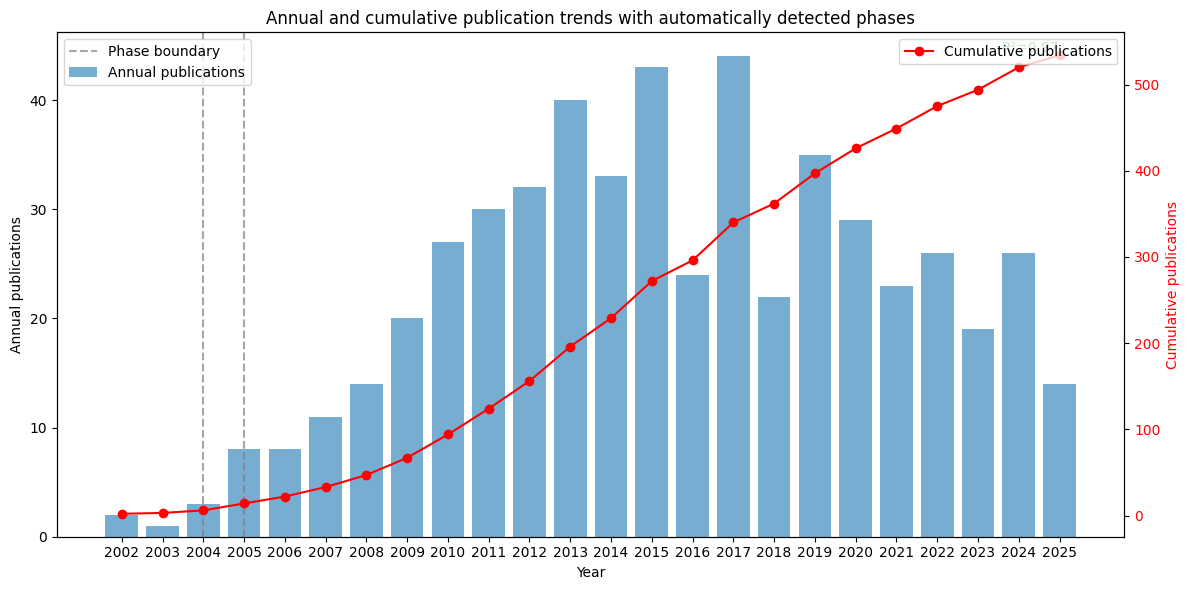

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig


# Helper functions
def auto_detect_num_phases(annual_df, growth_col="growth_pct", min_phases=1, max_phases=6):
    jumps = annual_df[growth_col].abs().dropna().to_numpy()
    if jumps.size == 0:
        return 1

    threshold = 0.5 * jumps.max()
    phases = int((jumps > threshold).sum()) + 1
    return max(min_phases, min(phases, max_phases))


def detect_phases_auto(annual_df, year_col="year", growth_col="growth_pct", max_phases=3):
    years = annual_df[year_col].tolist()
    growth = annual_df[growth_col].tolist()

    if not years:
        return [], []

    if max_phases <= 1:
        return [(years[0], years[-1])], []

    valid_indices = [i for i in range(1, len(years)) if not np.isnan(growth[i])]
    if not valid_indices:
        return [(years[0], years[-1])], []

    num_breakpoints = min(max_phases - 1, len(valid_indices))
    if num_breakpoints <= 0:
        return [(years[0], years[-1])], []

    growth_values = np.abs([growth[i] for i in valid_indices])
    top_indices = np.argsort(-np.array(growth_values))[:num_breakpoints]
    breakpoints = sorted(years[valid_indices[i]] for i in top_indices)

    phases = []
    start_year = years[0]
    for bp in breakpoints:
        phases.append((start_year, bp - 1))
        start_year = bp
    phases.append((start_year, years[-1]))

    return phases, breakpoints


def summarize_phase(annual_df, start_year, end_year, year_col="year"):
    subset = annual_df[
        (annual_df[year_col] >= start_year) &
        (annual_df[year_col] <= end_year)
    ]

    if subset.empty:
        return {
            "start": int(start_year),
            "end": int(end_year),
            "n_years": 0,
            "total_pubs": 0,
            "mean_per_year": 0.0,
            "min_per_year": 0,
            "max_per_year": 0,
        }

    annual_count = subset["annual_count"]
    return {
        "start": int(start_year),
        "end": int(end_year),
        "n_years": int(len(subset)),
        "total_pubs": int(annual_count.sum()),
        "mean_per_year": float(annual_count.mean()),
        "min_per_year": int(annual_count.min()),
        "max_per_year": int(annual_count.max()),
    }


# ----------------------Main Use-------------------------
df = DATASET()

df = df[df["year"].notna()].copy()
df["year"] = df["year"].astype(str).str.strip()
df = df[df["year"] != ""].copy()
df["year"] = df["year"].astype(int)

annual_counts = (
    df.groupby("year")
    .size()
    .reset_index(name="annual_count")
    .sort_values("year")
    .reset_index(drop=True)
)

annual_counts["cumulative_count"] = annual_counts["annual_count"].cumsum()
annual_counts["growth_pct"] = annual_counts["annual_count"].pct_change() * 100

X = annual_counts[["year"]].to_numpy()
y = annual_counts["cumulative_count"].to_numpy()

model = LinearRegression()
model.fit(X, y)
r2 = r2_score(y, model.predict(X))

auto_num_phases = auto_detect_num_phases(annual_counts)
print(f"Automatically selected number of phases: {auto_num_phases}")

phases, breakpoints = detect_phases_auto(annual_counts, max_phases=auto_num_phases)
phase_stats = [summarize_phase(annual_counts, start, end) for start, end in phases]
phase_stats_df = pd.DataFrame(phase_stats)

print("Detected phases and their statistics:")
for i, stats in enumerate(phase_stats, start=1):
    print(
        f"Phase {i}: {stats['start']}–{stats['end']} | "
        f"years={stats['n_years']}, total={stats['total_pubs']}, "
        f"mean/year={stats['mean_per_year']:.2f}, "
        f"min/year={stats['min_per_year']}, "
        f"max/year={stats['max_per_year']}"
    )

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(
    annual_counts["year"],
    annual_counts["annual_count"],
    alpha=0.6,
    label="Annual publications",
)
ax1.set_xlabel("Year")
ax1.set_ylabel("Annual publications")
ax1.tick_params(axis="y")

ax2 = ax1.twinx()
ax2.plot(
    annual_counts["year"],
    annual_counts["cumulative_count"],
    color="red",
    marker="o",
    label="Cumulative publications",
)
ax2.set_ylabel("Cumulative publications", color="red")
ax2.tick_params(axis="y", labelcolor="red")

for i, bp in enumerate(breakpoints):
    ax1.axvline(
        x=bp,
        linestyle="--",
        color="gray",
        alpha=0.7,
        label="Phase boundary" if i == 0 else None,
    )

plt.title("Annual and cumulative publication trends with automatically detected phases")
plt.xticks(annual_counts["year"], rotation=45, ha="right")

ax2.text(
    annual_counts["year"].iloc[-1],
    annual_counts["cumulative_count"].iloc[-1],
    f"R²={r2:.2f}",
    color="green",
    fontsize=10,
    ha="right",
    va="bottom",
)

ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.tight_layout()
plt_savefig(plt, "publication_trends_with_auto_phases.png")
plt.show()

### Growth Rate Analysis (CAGR) 
CAGR quantifies the average annual growth rate of publications over time using a compound growth model: 


$$
CAGR = \left( \frac{V_{final}}{V_{initial}} \right)^{\frac{1}{n-1}} - 1
$$

Overall CAGR (decimal): 0.0883
Overall CAGR (percent): 8.83%


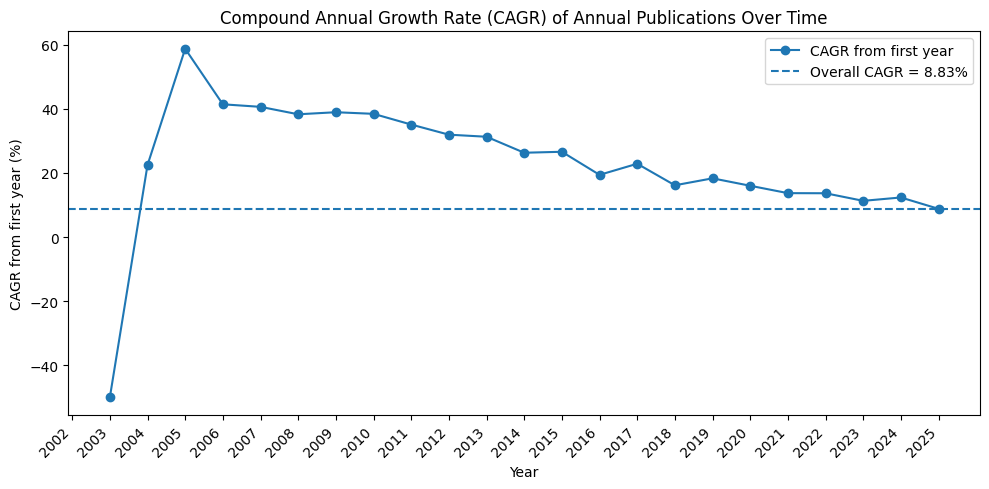

The compound annual growth rate (CAGR) of annual publications over the study period was 8.83%.


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig


# Load and clean dataset
df = DATASET()

df = df[df["year"].notna()].copy()
df["year"] = pd.to_numeric(df["year"].astype(str).str.strip(), errors="coerce")
df = df[df["year"].notna()].copy()
df["year"] = df["year"].astype(int)


# Compute annual publication counts
annual_counts = (
    df.groupby("year")
    .size()
    .reset_index(name="annual_count")
    .sort_values("year")
    .reset_index(drop=True)
)


# Compute CAGR
first_value = annual_counts["annual_count"].iloc[0]
last_value = annual_counts["annual_count"].iloc[-1]
n_years = len(annual_counts) - 1

overall_cagr = (
    (last_value / first_value) ** (1 / n_years) - 1
    if first_value > 0 and n_years > 0
    else np.nan
)

annual_counts["cagr_from_start"] = [
    np.nan if i == 0 or first_value <= 0
    else (annual_counts["annual_count"].iloc[i] / first_value) ** (1 / i) - 1
    for i in range(len(annual_counts))
]

print(f"Overall CAGR (decimal): {overall_cagr:.4f}")
print(f"Overall CAGR (percent): {overall_cagr * 100:.2f}%")


# Plot CAGR
plt.figure(figsize=(10, 5))
plt.plot(
    annual_counts["year"],
    annual_counts["cagr_from_start"] * 100,
    marker="o",
    linestyle="-",
    label="CAGR from first year",
)

if not np.isnan(overall_cagr):
    plt.axhline(
        y=overall_cagr * 100,
        linestyle="--",
        label=f"Overall CAGR = {overall_cagr * 100:.2f}%",
    )

plt.xlabel("Year")
plt.ylabel("CAGR from first year (%)")
plt.title("Compound Annual Growth Rate (CAGR) of Annual Publications Over Time")
plt.xticks(annual_counts["year"], rotation=45, ha="right")
plt.legend()
plt.tight_layout()

plt_savefig(plt, "cagr_over_time.png")
plt.show()


# Manuscript sentence
if not np.isnan(overall_cagr):
    print(
        f"The compound annual growth rate (CAGR) of annual publications over the study period "
        f"was {overall_cagr * 100:.2f}%."
    )

### Annual and Cumulative Publication Trends
This analysis compares yearly publication counts with cumulative growth trajectories to assess long-term expansion trends in the field.

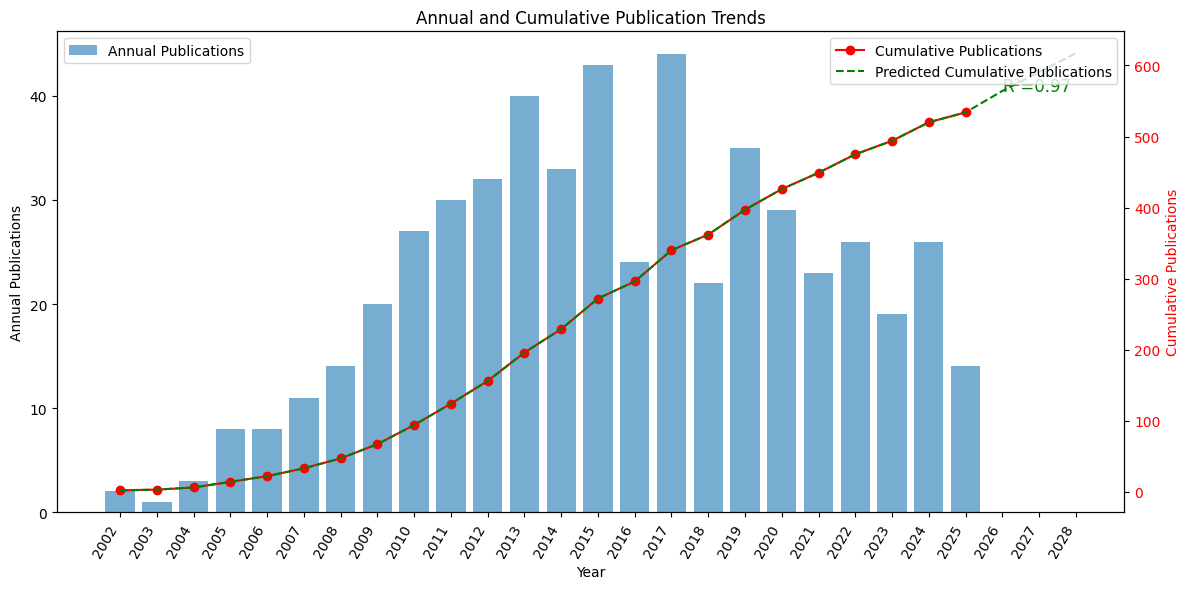

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig


# ----------------------Main Use-------------------------
df = DATASET()

df = df[df["year"].notna()].copy()
df["year"] = pd.to_numeric(df["year"].astype(str).str.strip(), errors="coerce")
df = df[df["year"].notna()].copy()
df["year"] = df["year"].astype(int)

annual_counts = (
    df.groupby("year")
    .size()
    .reset_index(name="annual_count")
    .sort_values("year")
    .reset_index(drop=True)
)
annual_counts["cumulative_count"] = annual_counts["annual_count"].cumsum()

X = annual_counts[["year"]].to_numpy()
y = annual_counts["cumulative_count"].to_numpy()

model = LinearRegression().fit(X, y)
r2 = r2_score(y, model.predict(X))

last_year = annual_counts["year"].max()
future_years = np.arange(last_year + 1, last_year + 4).reshape(-1, 1)
future_predictions = model.predict(future_years)

predicted_years = np.concatenate([annual_counts["year"].to_numpy(), future_years.ravel()])
predicted_cumulative = np.concatenate([y, future_predictions])

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(
    annual_counts["year"],
    annual_counts["annual_count"],
    alpha=0.6,
    label="Annual Publications",
)
ax1.set_xlabel("Year")
ax1.set_ylabel("Annual Publications")

ax2 = ax1.twinx()
ax2.plot(
    annual_counts["year"],
    annual_counts["cumulative_count"],
    color="red",
    marker="o",
    label="Cumulative Publications",
)
ax2.plot(
    predicted_years,
    predicted_cumulative,
    color="green",
    linestyle="dashed",
    label="Predicted Cumulative Publications",
)
ax2.set_ylabel("Cumulative Publications", color="red")
ax2.tick_params(axis="y", labelcolor="red")

plt.title("Annual and Cumulative Publication Trends")
ax1.set_xticks(np.sort(predicted_years))
ax1.set_xticklabels(np.sort(predicted_years), rotation=60, ha="right")

ax1.legend(loc="upper left")
ax2.legend(loc="upper right")
ax2.text(
    future_years[0, 0],
    future_predictions[0],
    f"R²={r2:.2f}",
    color="green",
    fontsize=12,
)

plt.tight_layout()
plt_savefig(plt, "annual_and_cumulative_publication_trends.png")
plt.show()

## Citation Analysis

### Top-Cited Publications
The most highly cited articles are identified to highlight influential works shaping the field. Citation counts serve as a proxy for scientific impact.

✅ `top_most_cited_article.csv` as CSV saved. 


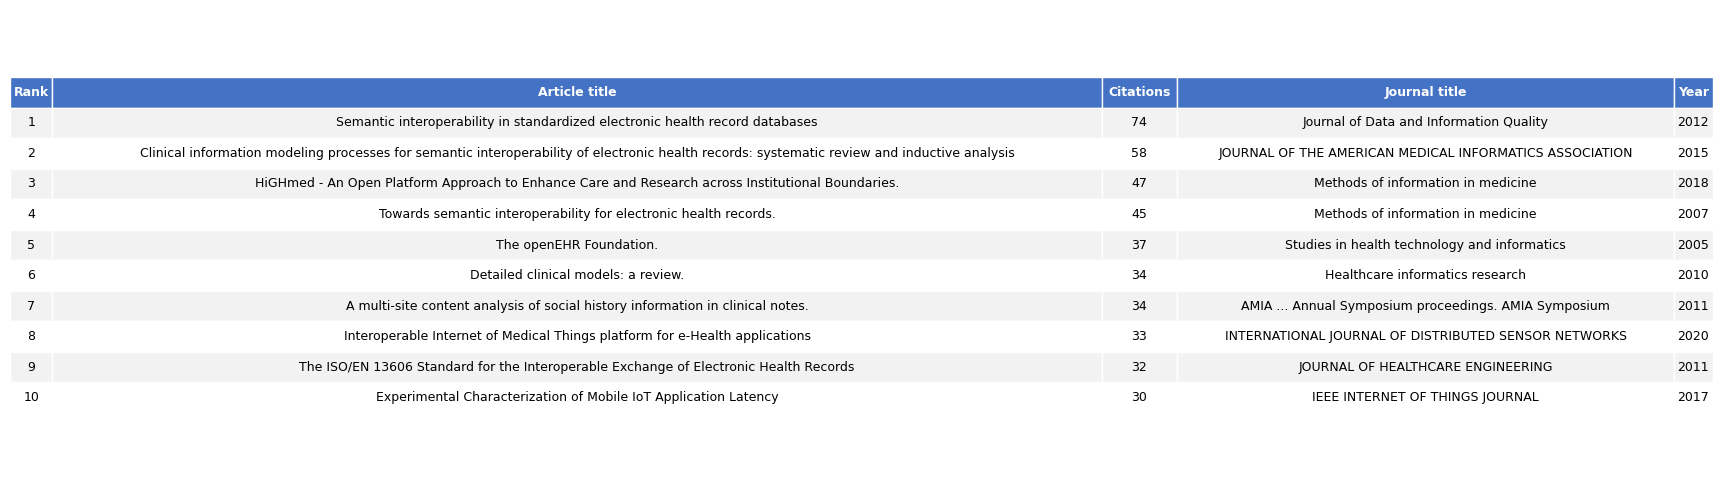

In [8]:
import matplotlib.pyplot as plt

from src.lib_dataset import DATASET
from src.lib_visualization import dataframe_to_csv, plt_savefig


# ----------------------Main Use-------------------------
df = DATASET()

top_df = (
    df.sort_values("citation_count", ascending=False)
    .reset_index(drop=True)
)

top_df["Rank"] = top_df.index + 1

dataframe_to_csv(top_df, "top_most_cited_article.csv")

top10 = top_df.head(10)[["Rank", "title", "citation_count", "publisher", "year"]]
top10.columns = ["Rank", "Article title", "Citations", "Journal title", "Year"]

fig, ax = plt.subplots(figsize=(16, 5))
ax.axis("off")

table = ax.table(
    cellText=top10.values,
    colLabels=top10.columns,
    cellLoc="center",
    loc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("w")
    if row == 0:
        cell.set_facecolor("#4472C4")
        cell.set_text_props(weight="bold", color="w")
    elif row % 2 == 1:
        cell.set_facecolor("#F2F2F2")

table.auto_set_column_width(col=list(range(len(top10.columns))))

plt.tight_layout()
plt_savefig(plt, "top_most_cited_article.png")
plt.show()

### Publication–Citation Dynamics Over Time
This analysis examines the relationship between publication volume and citation accumulation over time, revealing lag effects and impact trends.

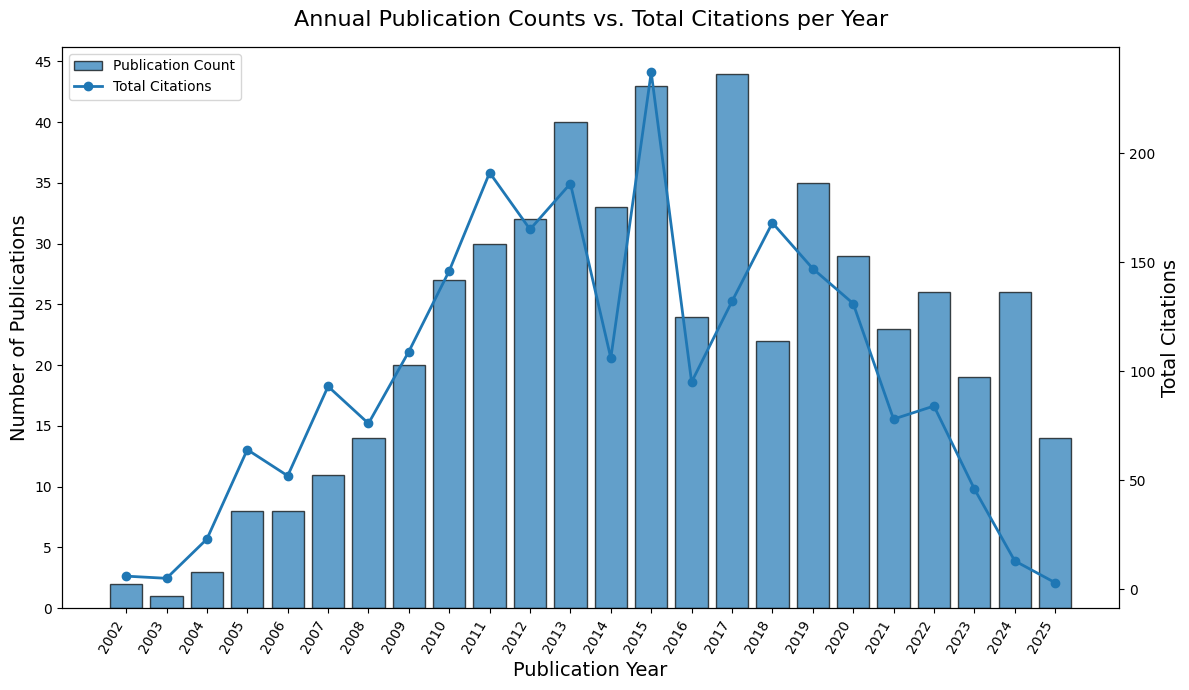

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig


# ----------------------Main Use-------------------------
df = DATASET()

df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["citation_count"] = pd.to_numeric(df["citation_count"], errors="coerce").fillna(0).astype(int)

df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)

annual_metrics_df = (
    df.groupby("year", as_index=False)
    .agg(
        Publication_Count=("DBUID", "count"),
        Total_Citations=("citation_count", "sum"),
    )
    .sort_values("year")
)

annual_metrics_df["Publication_Count"] = annual_metrics_df["Publication_Count"].astype(int)
annual_metrics_df["Total_Citations"] = annual_metrics_df["Total_Citations"].astype(int)

years = annual_metrics_df["year"]
pub_counts = annual_metrics_df["Publication_Count"]
total_cites = annual_metrics_df["Total_Citations"]

fig, ax1 = plt.subplots(figsize=(12, 7))

bars = ax1.bar(years, pub_counts, alpha=0.7, edgecolor="black", label="Publication Count")
ax1.set_xlabel("Publication Year", fontsize=14)
ax1.set_ylabel("Number of Publications", fontsize=14)
ax1.yaxis.set_major_locator(MaxNLocator(integer=True))
ax1.set_xticks(years)
ax1.set_xticklabels(years, rotation=60, ha="right")

ax2 = ax1.twinx()
line = ax2.plot(years, total_cites, marker="o", linewidth=2, label="Total Citations")
ax2.set_ylabel("Total Citations", fontsize=14)

ax1.legend([bars, line[0]], ["Publication Count", "Total Citations"], loc="upper left")

plt.title("Annual Publication Counts vs. Total Citations per Year", fontsize=16, pad=15)
plt.tight_layout()

plt_savefig(plt, "annual_publications_vs_citations_dual_axis.png")
plt.show()
plt.close()

### Normalized Citation Impact Over Time
To reduce the temporal bias inherent in raw citation counts, citation impact was normalized by article age. For each publication, citations per year were calculated as total citations divided by the number of years since publication. Annual mean and median normalized citation impact were then plotted alongside publication counts to compare research output with age-adjusted scholarly influence over time.

$$
\text{Citations per Year} = \frac{\text{Total Citations}}{\text{2025 - Publication Year + 1}}
$$

✅ `normalized_citation_impact_by_year.csv` as CSV saved. 


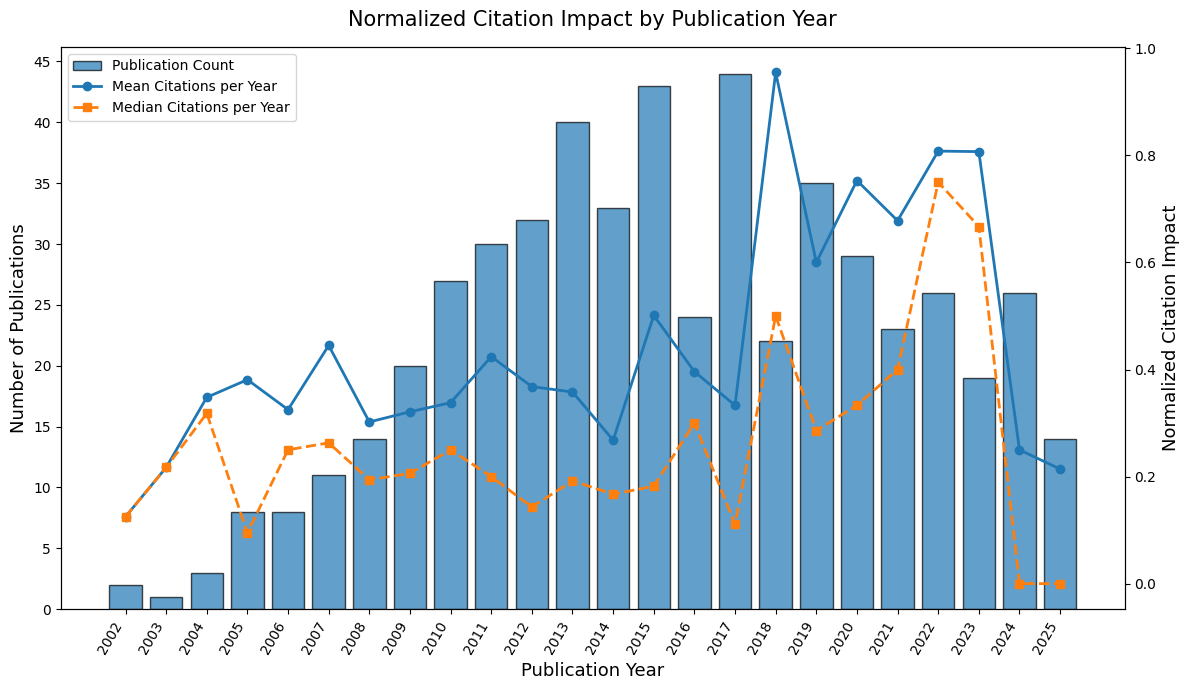

The highest mean normalized citation impact was observed in 2018 (0.95 citations per year).
The highest median normalized citation impact was observed in 2022 (0.75 citations per year).


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

# ---------------------- Settings -------------------------
END_YEAR = 2025

df = DATASET()

# Load and clean
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["citation_count"] = pd.to_numeric(df["citation_count"], errors="coerce").fillna(0)

df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)

df = df[(df["year"] > 0) & (df["year"] <= END_YEAR)].copy()

if df.empty:
    raise ValueError("No valid publication years found for normalized citation analysis.")

# Compute normalized citations
df["article_age"] = END_YEAR - df["year"] + 1
df["citations_per_year"] = df["citation_count"] / df["article_age"]

# Aggregate by publication year
yearly_norm_df = (
    df.groupby("year", as_index=False)
    .agg(
        Publication_Count=("DBUID", "count"),
        Total_Citations=("citation_count", "sum"),
        Mean_Citations_Per_Year=("citations_per_year", "mean"),
        Median_Citations_Per_Year=("citations_per_year", "median"),
    )
    .sort_values("year")
    .reset_index(drop=True)
)

yearly_norm_df["Publication_Count"] = yearly_norm_df["Publication_Count"].astype(int)
yearly_norm_df["Total_Citations"] = yearly_norm_df["Total_Citations"].round(2)
yearly_norm_df["Mean_Citations_Per_Year"] = yearly_norm_df["Mean_Citations_Per_Year"].round(3)
yearly_norm_df["Median_Citations_Per_Year"] = yearly_norm_df["Median_Citations_Per_Year"].round(3)

dataframe_to_csv(yearly_norm_df, "normalized_citation_impact_by_year.csv")

# Plot
fig, ax1 = plt.subplots(figsize=(12, 7))

bars = ax1.bar(
    yearly_norm_df["year"],
    yearly_norm_df["Publication_Count"],
    alpha=0.7,
    edgecolor="black",
    label="Publication Count"
)

ax1.set_xlabel("Publication Year", fontsize=13)
ax1.set_ylabel("Number of Publications", fontsize=13)
ax1.yaxis.set_major_locator(MaxNLocator(integer=True))
ax1.set_xticks(yearly_norm_df["year"])
ax1.set_xticklabels(yearly_norm_df["year"], rotation=60, ha="right")

ax2 = ax1.twinx()

line1 = ax2.plot(
    yearly_norm_df["year"],
    yearly_norm_df["Mean_Citations_Per_Year"],
    marker="o",
    linewidth=2,
    label="Mean Citations per Year"
)

line2 = ax2.plot(
    yearly_norm_df["year"],
    yearly_norm_df["Median_Citations_Per_Year"],
    marker="s",
    linewidth=2,
    linestyle="--",
    label="Median Citations per Year"
)

ax2.set_ylabel("Normalized Citation Impact", fontsize=13)

handles = [bars, line1[0], line2[0]]
labels = ["Publication Count", "Mean Citations per Year", "Median Citations per Year"]
ax1.legend(handles, labels, loc="upper left")

plt.title("Normalized Citation Impact by Publication Year", fontsize=15, pad=15)
plt.tight_layout()

plt_savefig(plt, "normalized_citation_impact_by_year.png")
plt.show()
plt.close()

# Manuscript text
peak_mean_row = yearly_norm_df.loc[yearly_norm_df["Mean_Citations_Per_Year"].idxmax()]
peak_median_row = yearly_norm_df.loc[yearly_norm_df["Median_Citations_Per_Year"].idxmax()]

print(
    f"The highest mean normalized citation impact was observed in {int(peak_mean_row['year'])} "
    f"({peak_mean_row['Mean_Citations_Per_Year']:.2f} citations per year)."
)

print(
    f"The highest median normalized citation impact was observed in {int(peak_median_row['year'])} "
    f"({peak_median_row['Median_Citations_Per_Year']:.2f} citations per year)."
)

## Geographic Analysis

### Leading Contributing Countries
Countries are ranked based on publication output, with additional metrics including citation counts and percentage contribution.

✅ `countries_by_publication.csv` as CSV saved. 


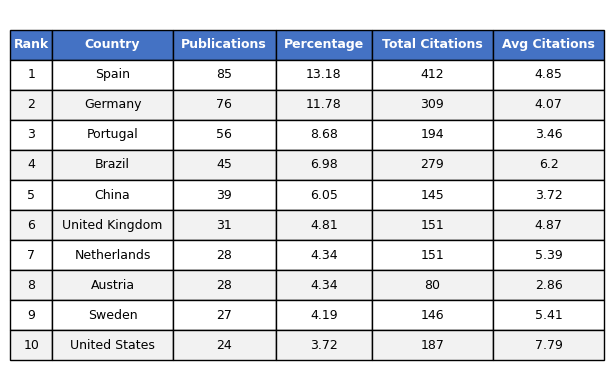

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()

country_stats = (
    df.explode("affiliation_country")
    .groupby("affiliation_country", dropna=False)
    .agg(Publications=("title", "count"), **{"Total Citations": ("citation_count", "sum")})
    .reset_index()
)

total_publications = country_stats["Publications"].sum()
country_stats["Percentage"] = country_stats["Publications"] / total_publications * 100
country_stats["Avg Citations"] = (
    country_stats["Total Citations"] / country_stats["Publications"]
)

dataframe_to_csv(country_stats, "countries_by_publication.csv")

country_stats = (
    country_stats.sort_values("Publications", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

country_stats["Rank"] = country_stats.index + 1
country_stats = country_stats[
    ["Rank", "affiliation_country", "Publications", "Percentage", "Total Citations", "Avg Citations"]
].rename(columns={"affiliation_country": "Country"})

numeric_columns = ["Publications", "Percentage", "Total Citations", "Avg Citations"]
country_stats[numeric_columns] = (
    country_stats[numeric_columns].apply(pd.to_numeric, errors="coerce").round(2)
)

fig, ax = plt.subplots(figsize=(5, 4))
ax.axis("off")

table = ax.table(
    cellText=country_stats.values,
    colLabels=country_stats.columns,
    loc="center",
    cellLoc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)
table.auto_set_column_width(col=list(range(len(country_stats.columns))))

for j in range(len(country_stats.columns)):
    cell = table[(0, j)]
    cell.set_facecolor("#4472C4")
    cell.set_text_props(color="white", weight="bold")

for i in range(1, len(country_stats) + 1):
    for j in range(len(country_stats.columns)):
        table[(i, j)].set_facecolor("#F2F2F2" if i % 2 == 0 else "white")

plt.tight_layout()
plt_savefig(plt, "top_10_countries_by_publication.png")
plt.show()

### Global Distribution of Publications and Citation Impact
A choropleth map visualizes publication distribution across countries, while bubble overlays represent average citation impact, highlighting geographic disparities.

In [13]:
import ast
import pandas as pd
import plotly.express as px
from src.config import OUTPUT_DIR
from src.lib_dataset import DATASET

# World Choropleth of Publication Counts with Bubbles for Mean Citations per Country

CHOROPLETH_MIN_PUBLICATIONS = 1
BUBBLE_MIN_PUBLICATIONS = 2

df = DATASET()

def safe_eval(val):
    if isinstance(val, list):
        return val
    if not isinstance(val, str):
        return [] if pd.isna(val) else [val]
    try:
        out = ast.literal_eval(val)
        return out if isinstance(out, list) else [out]
    except:
        return [] if pd.isna(val) else [val]

df["affiliation_country"] = df["affiliation_country"].apply(safe_eval)
df["citation_count"] = pd.to_numeric(df["citation_count"], errors="coerce").fillna(0)

df_c = df.explode("affiliation_country").copy()
df_c["affiliation_country"] = df_c["affiliation_country"].astype(str).str.strip().replace({"": pd.NA})
df_c = df_c.dropna(subset=["affiliation_country"])

# Create ISO-3 code mapping for countries
country_to_iso3 = {
    "United States": "USA",
    "China": "CHN",
    "United Kingdom": "GBR",
    "Germany": "DEU",
    "France": "FRA",
    "Japan": "JPN",
    "Canada": "CAN",
    "Italy": "ITA",
    "India": "IND",
    "Australia": "AUS",
    "Brazil": "BRA",
    "South Korea": "KOR",
    "Netherlands": "NLD",
    "Spain": "ESP",
    "Switzerland": "CHE",
    "Sweden": "SWE",
    "Belgium": "BEL",
    "Israel": "ISR",
    "Denmark": "DNK",
    "Norway": "NOR",
    "Finland": "FIN",
    "Austria": "AUT",
    "Poland": "POL",
    "Russia": "RUS",
    "Turkey": "TUR",
    "Iran": "IRN",
    "Taiwan": "TWN",
    "Singapore": "SGP",
    "Hong Kong": "HKG",
}

def get_iso3(country_name):
    return country_to_iso3.get(country_name, country_name)

df_c["Country_ISO3"] = df_c["affiliation_country"].apply(get_iso3)

country_stats_df = (
    df_c.groupby("Country_ISO3", as_index=False)
    .agg(
        Publication_Count=("DBUID", "nunique"),
        Mean_Citations=("citation_count", "mean"),
        Country_Name=("affiliation_country", "first"),
    )
)
country_stats_df["Mean_Citations"] = country_stats_df["Mean_Citations"].round(2)

choropleth_df = country_stats_df[country_stats_df["Publication_Count"] >= CHOROPLETH_MIN_PUBLICATIONS]
bubble_df = country_stats_df[country_stats_df["Publication_Count"] >= BUBBLE_MIN_PUBLICATIONS]

fig_choro = px.choropleth(
    choropleth_df,
    locations="Country_ISO3",
    color="Publication_Count",
    color_continuous_scale="Viridis",
    labels={"Publication_Count": "Publication Count"},
)

fig_bubble = px.scatter_geo(
    bubble_df,
    locations="Country_ISO3",
    size="Mean_Citations",
    hover_name="Country_Name",
    hover_data={
        "Publication_Count": True,
        "Mean_Citations": True,
        "Country_ISO3": False,
        "Country_Name": False,
    },
)

fig = fig_choro
for trace in fig_bubble.data:
    fig.add_trace(trace)

fig.update_layout(title={"text": "World Choropleth of Publication Counts with Bubbles for Mean Citations", "x": 0.5})

try:
    fig.write_image(str(OUTPUT_DIR / "world_choropleth_publications_mean_citations.png"), format="png", scale=2)
    print("Saved PNG: world_choropleth_publications_mean_citations.png")
except Exception as e:
    print(f"Could not save PNG (Plotly static export error): {e}")

print("Static world map created (PNG only).")

Could not save PNG (Plotly static export error): 
Image export using the "kaleido" engine requires the Kaleido package,
which can be installed using pip:

    $ pip install --upgrade kaleido

Static world map created (PNG only).


![world_choropleth_publications_mean_citations](./output/world_choropleth_publications_mean_citations.png)

### Cartogram of Country-Level Publication Intensity
A cartogram distorts country sizes proportionally to publication output, emphasizing dominant contributors in the global research landscape.

Use [SCImago Graphica](https://www.graphica.app/)
A cartogram is a map in which the size and shape of the different regions are distorted to depict the values of a quantitative variable.

To create a cartogram:
- Link a geographic variable (Country) to 'unit' and in Marks select 'filled map'.
- Link a quantitative variable to ‘Size’.

In [15]:
import pandas as pd
from collections import Counter, defaultdict
import pycountry
from src.lib_dataset import DATASET
from src.lib_visualization import dataframe_to_csv

df = DATASET()

# Manual country normalization mapping
manual_mapping = {
    "russia": "Russian Federation",
    "korea": "South Korea",        
    "south korea": "South Korea",
    "north korea": "North Korea",
    "turkey": "Türkiye",
    "iran": "Iran, Islamic Republic of",
    "vietnam": "Viet Nam",
    "bolivia": "Bolivia, Plurinational State of",
    "tanzania": "Tanzania, United Republic of",
    "syria": "Syrian Arab Republic",
    "laos": "Lao People's Democratic Republic",
    "moldova": "Moldova, Republic of",
    "venezuela": "Venezuela, Bolivarian Republic of",
}

def normalize_country_name(name):
    key = str(name).strip().lower()
    return manual_mapping.get(key, name)

pub_counter = Counter()
cit_counter = defaultdict(int)

for i, row in df.iterrows():
    countries = row["affiliation_country"]
    citations = row.get("citation_count", 0)

    if not countries:
        continue

    for c in countries:
        std = normalize_country_name(c)
        pub_counter[std] += 1
        cit_counter[std] += int(citations)

country_df = pd.DataFrame([
    {
        "country": country,
        "n_publications": pub_counter[country],
        "total_citations": cit_counter[country],
    }
    for country in pub_counter
])

def get_iso3(name):
    try:
        return pycountry.countries.lookup(name).alpha_3
    except:
        return None

country_df["iso3"] = country_df["country"].apply(get_iso3)
country_df = country_df.sort_values("n_publications", ascending=False).reset_index(drop=True)

dataframe_to_csv(country_df, "country_list_for_cartogram.csv")

✅ `country_list_for_cartogram.csv` as CSV saved. 


![cartogram](./output/cartogram.png)

## Collaboration Analysis

### International Collaboration Rate (ICR) Over Time
ICR is defined as the proportion of publications with authors from multiple countries.

To quantify the degree of cross-national research cooperation, we computed the **International Collaboration Rate (ICR)**, which measures the share of publications co-authored by researchers affiliated with **two or more distinct countries**. An article is classified as internationally collaborative if its affiliation list includes contributors from at least two different national origins. The ICR is formally defined as:

$$
ICR = \frac{N_{\text{international}}}{N_{\text{total}}}
$$

where $ N_{\text{international}} $ denotes the number of internationally co-authored articles, and $ N_{\text{total}} $ represents the total number of articles in the dataset. Higher ICR values indicate stronger global interconnectedness and a greater reliance on cross-border scholarly collaboration.

Overall International Collaboration Rate (ICR): 0.121


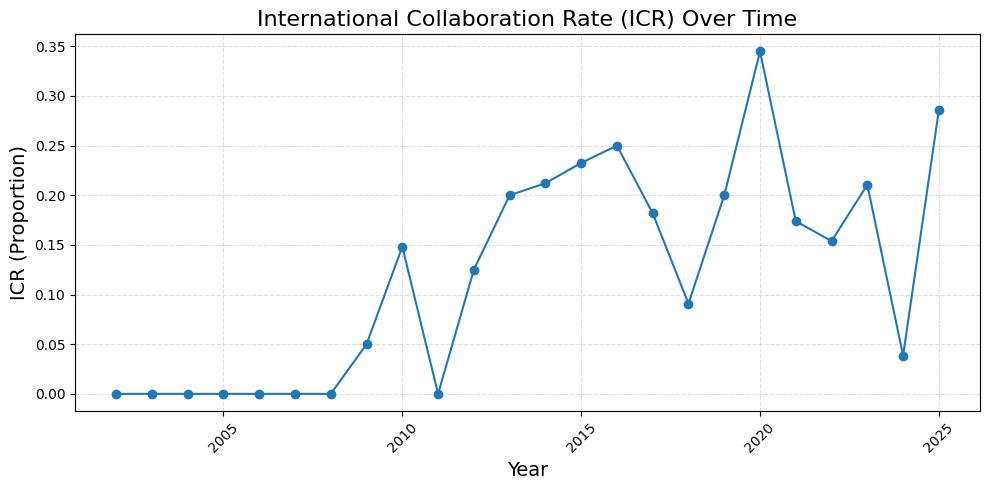

✅ `international_collaboration_rate_over_time.csv` as CSV saved. 


In [16]:
import ast

import matplotlib.pyplot as plt
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()


# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


df = df.rename(
    columns={
        "affiliation_integration_country": "affiliation_country",
    }
)

df["affiliation_country"] = df["affiliation_country"].apply(safe_eval)
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)

icr_df = (
    df.assign(
        is_international=df["affiliation_country"].apply(
            lambda countries: len({c for c in countries if isinstance(c, str) and c.strip()}) >= 2
        )
    )
    .groupby("year", as_index=False)["is_international"]
    .mean()
    .rename(columns={"year": "Year", "is_international": "ICR"})
    .sort_values("Year")
)

overall_icr = icr_df["ICR"].mean() if not icr_df.empty else 0.0
print(f"Overall International Collaboration Rate (ICR): {overall_icr:.3f}")

plt.figure(figsize=(10, 5))
plt.plot(icr_df["Year"], icr_df["ICR"], marker="o")
plt.title("International Collaboration Rate (ICR) Over Time", fontsize=16)
plt.xlabel("Year", fontsize=14)
plt.ylabel("ICR (Proportion)", fontsize=14)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

plt_savefig(plt, "international_collaboration_rate_over_time.png")
plt.show()
plt.close()

dataframe_to_csv(icr_df, "international_collaboration_rate_over_time.csv")

### Country Co-occurrence Network (VOSviewer Visualization)
A co-occurrence network of countries is constructed based on shared authorship, revealing collaboration clusters and international partnerships.

In [17]:
import json
import random
import os

from src.lib_co_occurrence import (
    convert_co_occurrence_matrix2graph,
    generate_co_occurrence_matrix,
)
from src.lib_dataset import DATASET
from src.lib_visualization import dataframe_to_csv

df = DATASET()

co_occurrence_matrix = generate_co_occurrence_matrix(df, "affiliation_country")
matrix_size = len(co_occurrence_matrix.columns)

print(f"Matrix: {matrix_size} * {matrix_size}")

dataframe_to_csv(co_occurrence_matrix, "country_co_occurrence_matrix.csv")

G = convert_co_occurrence_matrix2graph(co_occurrence_matrix, 2)
print(f"Converted to NetworkX graph. Number of nodes: {G.number_of_nodes()}")

graph_data = {
    "network": {
        "items": [
            {
                "id": node,
                "label": label or node,
                "x": round(random.uniform(-1.1515, 0.2000), 4),
                "y": round(random.uniform(-1.1515, 0.2000), 4),
            }
            for node, label in G.nodes(data="label")
        ],
        "links": [
            {
                "source_id": source,
                "target_id": target,
                "strength": data["weight"],
            }
            for source, target, data in G.edges(data=True)
        ],
    }
}


# ----------------------Main Use-------------------------
of = os.path.join(OUTPUT_DIR ,"vos_viewer_country_co_occurrence.json")
with open(of, "w", encoding="utf-8") as f:
    json.dump(graph_data, f, indent=4, ensure_ascii=False)
print("`vos_viewer_country_co_occurrence.json` saved.")

Matrix: 56 * 56
✅ `country_co_occurrence_matrix.csv` as CSV saved. 
Converted to NetworkX graph. Number of nodes: 29
`vos_viewer_country_co_occurrence.json` saved.


![vos_viewer_country_co_occurrence](./output/vos_viewer_country_co_occurrence.png)

## Author and Journal Analysis

### Most Influential Authors
Authors are ranked based on total citations and publication counts to identify key contributors and leaders in the field.

✅ `top_10_authors_in_research_impact.csv` as CSV saved. 


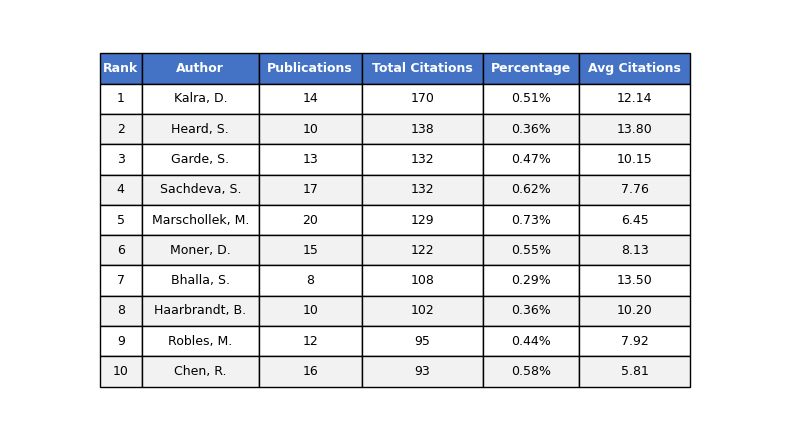

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()

authors_expanded = df.explode("authors").dropna(subset=["authors"]).copy()
authors_expanded["citation_count"] = pd.to_numeric(
    authors_expanded["citation_count"], errors="coerce"
).fillna(0)

author_stats = (
    authors_expanded.groupby("authors", as_index=False)
    .agg(
        Publications=("authors", "size"),
        Total_Citations=("citation_count", "sum"),
    )
    .sort_values("Total_Citations", ascending=False)
    .reset_index(drop=True)
)

total_publications = author_stats["Publications"].sum()
author_stats["Percentage"] = (
    author_stats["Publications"] / total_publications * 100
).round(2)
author_stats["Avg_Citations"] = (
    author_stats["Total_Citations"] / author_stats["Publications"]
).round(2)

dataframe_to_csv(author_stats, "top_10_authors_in_research_impact.csv")

top_10_authors = author_stats.head(10).copy()
top_10_authors.insert(0, "Rank", range(1, len(top_10_authors) + 1))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axis("off")

display_df = top_10_authors.rename(
    columns={
        "authors": "Author",
        "Total_Citations": "Total Citations",
        "Avg_Citations": "Avg Citations",
    }
).copy()

display_df["Total Citations"] = display_df["Total Citations"].astype(int)
display_df["Publications"] = display_df["Publications"].astype(int)
display_df["Percentage"] = display_df["Percentage"].map(lambda x: f"{x:.2f}%")
display_df["Avg Citations"] = display_df["Avg Citations"].map(lambda x: f"{x:.2f}")

table = ax.table(
    cellText=display_df.values,
    colLabels=display_df.columns,
    loc="center",
    cellLoc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.auto_set_column_width(col=list(range(len(display_df.columns))))
table.scale(1, 1.5)

for j in range(len(display_df.columns)):
    cell = table[(0, j)]
    cell.set_facecolor("#4472C4")
    cell.set_text_props(color="white", weight="bold")

for i in range(1, len(display_df) + 1):
    for j in range(len(display_df.columns)):
        table[(i, j)].set_facecolor("#F2F2F2" if i % 2 == 0 else "white")

plt.tight_layout()
plt_savefig(plt, "top_10_authors_in_research_impact.png")
plt.show()

### Lotka’s Law of Scientific Productivity
Lotka’s Law of Scientific Productivity describes the highly skewed distribution of publication output among authors within a research field. It states that the number of authors publishing $ n $ papers is inversely proportional to $ n^2 $, such that a small minority of highly productive authors account for a large share of the total literature, while most authors publish only one or a few papers. In its generalized form, Lotka’s Law can be expressed as:

$$
A_n = A_1 , n^{-\alpha}
$$

where $ A_n $ denotes the number of authors who have published exactly $ n $ papers, $ A_1 $ is the number of authors with a single publication, and $ \alpha $ is an exponent typically close to 2 in empirical studies. Applying Lotka’s Law allows us to model and evaluate the concentration of scientific productivity, identify core groups of prolific contributors, and compare authorship patterns across different disciplines or datasets.

Total unique authors: 1610
   n_papers  n_authors  Author_Share_%  Cumulative_Authors  Cumulative_Share_%
0         1       1180           73.29                1180               73.29
1         2        214           13.29                1394               86.58
2         3         93            5.78                1487               92.36
3         4         39            2.42                1526               94.78
4         5         23            1.43                1549               96.21
Estimated Lotka parameters:
  A_1 ≈ 1052.323
  alpha ≈ 2.350


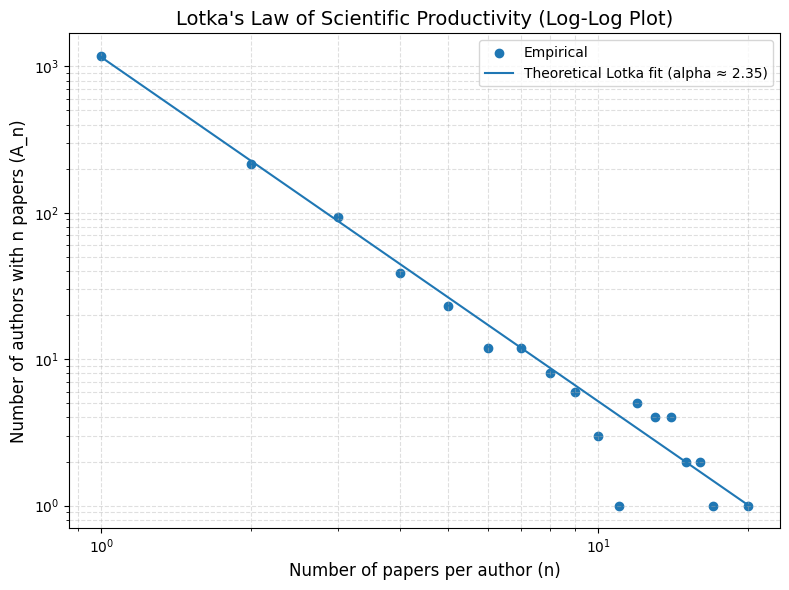

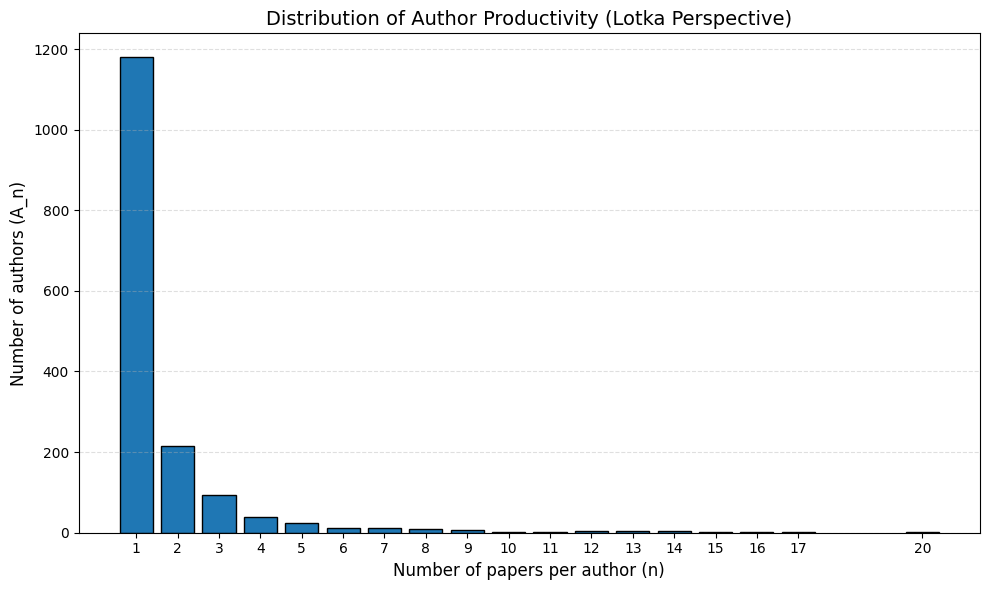

✅ `lotkas_law_author_productivity_distribution.csv` as CSV saved. 


In [19]:
import ast

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

YEAR_MIN = None
YEAR_MAX = None
MIN_PAPERS_FOR_FIT = 1

df = DATASET()


# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


df["authors"] = df["authors"].apply(safe_eval)
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)

if YEAR_MIN is not None:
    df = df[df["year"] >= YEAR_MIN]
if YEAR_MAX is not None:
    df = df[df["year"] <= YEAR_MAX]

if df.empty:
    raise ValueError("No articles available after year filtering for Lotka analysis.")

df_auth = df.explode("authors").dropna(subset=["authors"]).copy()
df_auth["authors"] = df_auth["authors"].astype(str).str.strip()
df_auth = df_auth[df_auth["authors"] != ""]

if df_auth.empty:
    raise ValueError("No author data available after exploding 'authors' for Lotka analysis.")

author_productivity = (
    df_auth.groupby("authors", as_index=False)
    .size()
    .rename(columns={"size": "n_papers"})
)

lotka_dist = (
    author_productivity["n_papers"]
    .value_counts()
    .sort_index()
    .rename_axis("n_papers")
    .reset_index(name="n_authors")
)

total_authors = lotka_dist["n_authors"].sum()
lotka_dist["Author_Share_%"] = (100 * lotka_dist["n_authors"] / total_authors).round(2)
lotka_dist["Cumulative_Authors"] = lotka_dist["n_authors"].cumsum()
lotka_dist["Cumulative_Share_%"] = (
    100 * lotka_dist["Cumulative_Authors"] / total_authors
).round(2)

print(f"Total unique authors: {total_authors}")
print(lotka_dist.head())

fit_data = lotka_dist[
    (lotka_dist["n_papers"] >= MIN_PAPERS_FOR_FIT) & (lotka_dist["n_authors"] > 0)
].copy()

if len(fit_data) < 2:
    raise ValueError("Not enough data points to fit Lotka's Law.")

x = np.log(fit_data["n_papers"].to_numpy())
y = np.log(fit_data["n_authors"].to_numpy())

b, a = np.polyfit(x, y, 1)
alpha_est = -b
a1_est = np.exp(a)

print("Estimated Lotka parameters:")
print(f"  A_1 ≈ {a1_est:.3f}")
print(f"  alpha ≈ {alpha_est:.3f}")

n_values = lotka_dist["n_papers"].to_numpy()
lotka_theoretical = a1_est * (n_values ** (-alpha_est))
lotka_dist["Lotka_Theoretical"] = lotka_theoretical * (
    total_authors / lotka_theoretical.sum()
)

plt.figure(figsize=(8, 6))
plt.scatter(
    lotka_dist["n_papers"],
    lotka_dist["n_authors"],
    label="Empirical",
    marker="o",
)
plt.plot(
    lotka_dist["n_papers"],
    lotka_dist["Lotka_Theoretical"],
    label=f"Theoretical Lotka fit (alpha ≈ {alpha_est:.2f})",
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of papers per author (n)", fontsize=12)
plt.ylabel("Number of authors with n papers (A_n)", fontsize=12)
plt.title("Lotka's Law of Scientific Productivity (Log-Log Plot)", fontsize=14)
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.tight_layout()
plt_savefig(plt, "lotkas_law_loglog_plot.png")
plt.show()
plt.close()

plt.figure(figsize=(10, 6))
plt.bar(
    lotka_dist["n_papers"],
    lotka_dist["n_authors"],
    edgecolor="black",
)
plt.xlabel("Number of papers per author (n)", fontsize=12)
plt.ylabel("Number of authors (A_n)", fontsize=12)
plt.title("Distribution of Author Productivity (Lotka Perspective)", fontsize=14)
plt.xticks(lotka_dist["n_papers"])
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt_savefig(plt, "lotkas_law_productivity_distribution.png")
plt.show()
plt.close()

dataframe_to_csv(lotka_dist, "lotkas_law_author_productivity_distribution.csv")

### Goodness-of-Fit Evaluation of Lotka Model
Model fit is evaluated using statistical measures including R², RMSE, MAE, and chi-square test to assess how well empirical data aligns with Lotka’s Law.

In [20]:
obs = lotka_dist["n_authors"].astype(float).to_numpy()
exp_ = lotka_dist["Lotka_Theoretical"].astype(float).to_numpy()

y_hat = a + b * x
ss_res = np.sum((y - y_hat) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
r2_loglog = 1 - ss_res / ss_tot if ss_tot != 0 else 0.0

rmse = np.sqrt(np.mean((obs - exp_) ** 2))
mae = np.mean(np.abs(obs - exp_))

mask = exp_ > 0
obs_cs = obs[mask]
exp_cs = exp_[mask]

chi2 = np.sum((obs_cs - exp_cs) ** 2 / exp_cs)
df_chi2 = max(len(obs_cs) - 3, 1)

try:
    from scipy.stats import chi2 as chi2_dist

    p_value = 1 - chi2_dist.cdf(chi2, df_chi2)
except Exception:
    p_value = None

print("Goodness-of-fit:")
print(f"  R^2 (log-log) = {r2_loglog:.4f}")
print(f"  RMSE (linear) = {rmse:.3f}")
print(f"  MAE (linear) = {mae:.3f}")
print(f"  Chi-square = {chi2:.3f} (df={df_chi2})")
if p_value is not None:
    print(f"  Chi-square p = {p_value:.4g}")

gof_text = (
    f"R² (log-log) = {r2_loglog:.3f}, "
    f"RMSE = {rmse:.2f}, MAE = {mae:.2f}, "
    + (
        f"χ²({df_chi2}) = {chi2:.2f}, p = {p_value:.3g}"
        if p_value is not None
        else f"χ²({df_chi2}) = {chi2:.2f}"
    )
)

print("\n[[lotka_goodness_of_fit]] replacement:")
print(gof_text)

Goodness-of-fit:
  R^2 (log-log) = 0.9521
  RMSE (linear) = 6.832
  MAE (linear) = 3.771
  Chi-square = 10.301 (df=15)
  Chi-square p = 0.8004

[[lotka_goodness_of_fit]] replacement:
R² (log-log) = 0.952, RMSE = 6.83, MAE = 3.77, χ²(15) = 10.30, p = 0.8


### Top Journals by Citation Performance
Journals are ranked by average citations per article (CPA), providing insight into publication venues with the highest impact.

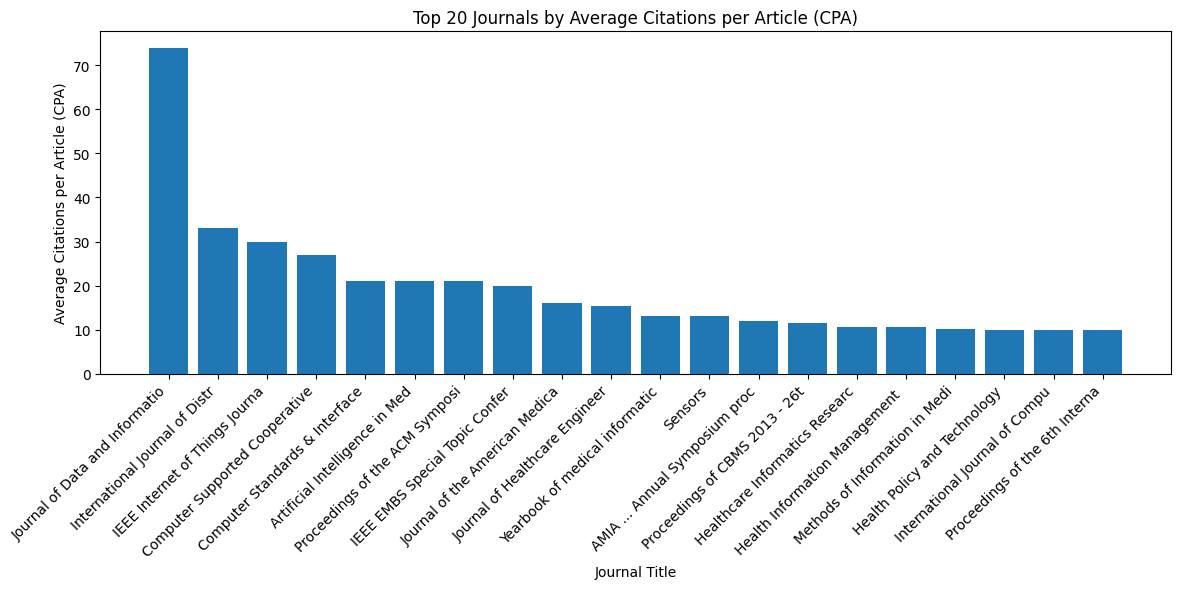

✅ `top_journal_by_cpa.csv` as CSV saved. 


In [21]:
import matplotlib.pyplot as plt
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()

top = 20

df["citation_count"] = pd.to_numeric(df["citation_count"], errors="coerce").fillna(0)

journal_stats = (
    df.groupby("journal_title", as_index=False)
    .agg(
        Total_Citations=("citation_count", "sum"),
        Publications=("journal_title", "size"),
    )
)

journal_stats["CPA"] = (
    journal_stats["Total_Citations"] / journal_stats["Publications"]
).round(2)

journal_stats_sorted = journal_stats.sort_values("CPA", ascending=False).reset_index(drop=True)
top_journals = journal_stats_sorted.head(top).copy()
top_journals["journal_title"] = top_journals["journal_title"].str.slice(0, 30)
title = f"Top {top} Journals by Average Citations per Article (CPA)"

plt.figure(figsize=(12, 6))
plt.bar(top_journals["journal_title"], top_journals["CPA"])
plt.xlabel("Journal Title")
plt.ylabel("Average Citations per Article (CPA)")
plt.title(title)
plt.xticks(rotation=45, ha="right")
plt.subplots_adjust(bottom=0.35)


plt_savefig(plt, "top_journal_by_cpa.png")
plt.show()

dataframe_to_csv(top_journals, "top_journal_by_cpa.csv")

### Journal Productivity vs. Citation Impact
This analysis compares journal output volume with citation performance to identify high-impact publication outlets.

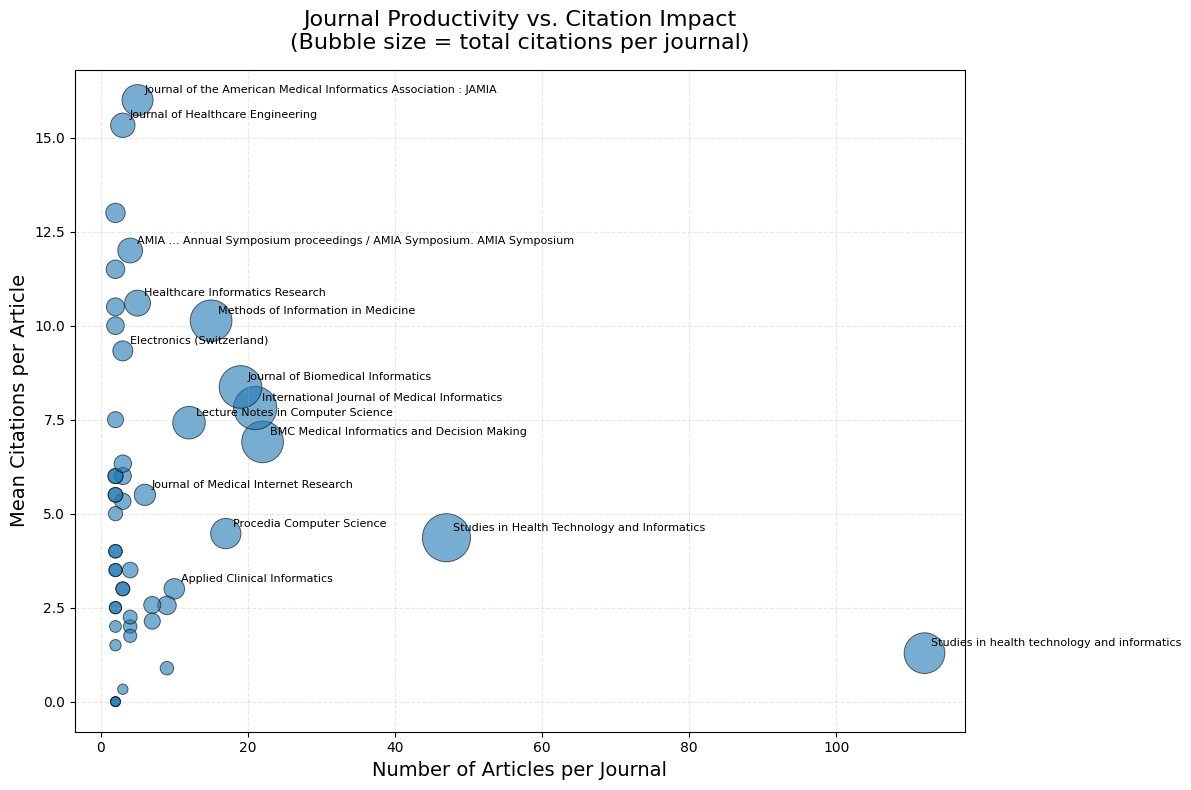

✅ `journal_productivity_vs_citation_impact.csv` as CSV saved. 


In [22]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

JOURNAL_KEY = "journal_title"
MIN_ARTICLES = 2
TOP_LABELS = 15
BASE_MARKER_SIZE = 50
MAX_MARKER_SIZE = 1200

df = DATASET()

df["citation_count"] = pd.to_numeric(df["citation_count"], errors="coerce").fillna(0)
df_journal = df.dropna(subset=[JOURNAL_KEY]).copy()

journal_stats_df = (
    df_journal.groupby(JOURNAL_KEY, as_index=False)
    .agg(
        Num_Articles=("DBUID", "nunique"),
        Total_Citations=("citation_count", "sum"),
        Mean_Citations=("citation_count", "mean"),
    )
    .rename(columns={JOURNAL_KEY: "Journal"})
)

journal_stats_df = journal_stats_df[journal_stats_df["Num_Articles"] >= MIN_ARTICLES].copy()
journal_stats_df["Num_Articles"] = journal_stats_df["Num_Articles"].fillna(0).astype(int)
journal_stats_df["Total_Citations"] = pd.to_numeric(
    journal_stats_df["Total_Citations"], errors="coerce"
).fillna(0)
journal_stats_df["Mean_Citations"] = pd.to_numeric(
    journal_stats_df["Mean_Citations"], errors="coerce"
).fillna(0).round(2)

if journal_stats_df.empty:
    print(f"No journals found with at least {MIN_ARTICLES} articles.")
else:
    max_total_citations = journal_stats_df["Total_Citations"].max()
    size_scaled = (
        [BASE_MARKER_SIZE] * len(journal_stats_df)
        if max_total_citations <= 0
        else BASE_MARKER_SIZE
        + (journal_stats_df["Total_Citations"] / max_total_citations)
        * (MAX_MARKER_SIZE - BASE_MARKER_SIZE)
    )

    plt.figure(figsize=(12, 8))
    plt.scatter(
        journal_stats_df["Num_Articles"],
        journal_stats_df["Mean_Citations"],
        s=size_scaled,
        alpha=0.6,
        edgecolor="black",
        linewidth=0.7,
    )

    plt.title(
        "Journal Productivity vs. Citation Impact\n"
        "(Bubble size = total citations per journal)",
        fontsize=16,
        pad=15,
    )
    plt.xlabel("Number of Articles per Journal", fontsize=14)
    plt.ylabel("Mean Citations per Article", fontsize=14)
    plt.gca().yaxis.set_major_locator(MaxNLocator(nbins=8))
    plt.grid(True, linestyle="--", alpha=0.3)

    top_journals = journal_stats_df.sort_values("Total_Citations", ascending=False).head(TOP_LABELS)
    for _, row in top_journals.iterrows():
        plt.annotate(
            row["Journal"],
            xy=(row["Num_Articles"], row["Mean_Citations"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8,
        )

    plt_savefig(plt, "journal_productivity_vs_citation_impact.png")
    plt.show()
    plt.close()

journal_stats_sorted = journal_stats_df.sort_values(
    "Total_Citations", ascending=False
).reset_index(drop=True)

dataframe_to_csv(
    journal_stats_sorted,
    "journal_productivity_vs_citation_impact.csv",
)

### Journal Quartile Distribution
Journals were categorized based on quartile rankings (e.g., Q1–Q4) to assess the quality and impact tier of publication venues. This distribution provides insight into the concentration of research across journal impact levels.

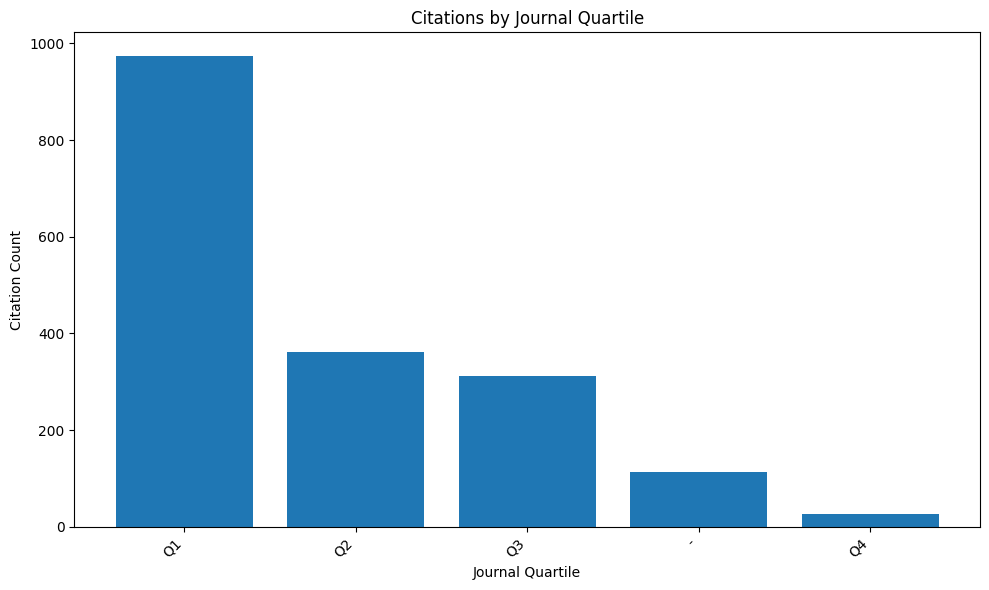

✅ `citations_by_journal_quartile.csv` as CSV saved. 


In [23]:
import matplotlib.pyplot as plt
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()

df["citation_count"] = pd.to_numeric(df["citation_count"], errors="coerce").fillna(0)

journal_stats = (
    df.dropna(subset=["journal_q"])
    .groupby("journal_q", as_index=False)
    .agg(
        Total_Citations=("citation_count", "sum"),
        Publications=("journal_title", "size"),
    )
    .sort_values("Total_Citations", ascending=False)
    .reset_index(drop=True)
)

journal_citation_sorted = journal_stats.head(30).copy()
title = "Citations by Journal Quartile"

plt.figure(figsize=(10, 6))
plt.bar(journal_citation_sorted["journal_q"], journal_citation_sorted["Total_Citations"])
plt.xlabel("Journal Quartile")
plt.ylabel("Citation Count")
plt.title(title)
plt.xticks(rotation=45, ha="right")
plt.subplots_adjust(bottom=0.2)

plt_savefig(plt, "citations_by_journal_quartile.png")
plt.show()

dataframe_to_csv(journal_citation_sorted, "citations_by_journal_quartile.csv")

### Bradford’s Law and Core Journal Identification
Bradford’s Law was applied to identify core journals contributing most publications. Journals were divided into zones where each zone contributes approximately equal numbers of articles, highlighting the concentration of knowledge sources.

Bradford’s Law of Scattering describes the distribution of relevant literature across scientific journals and is widely used to identify the core publication sources within a research field. According to this law, when journals are ranked in descending order of productivity (i.e., number of articles published on a given topic), they can be divided into groups or “zones” such that each zone contributes approximately the same number of relevant articles, but the number of journals required for each successive zone increases geometrically. Formally, if the first zone contains ( k ) core journals, then the number of journals in the subsequent zones tends to follow the ratio:

$$
1 : b : b^2 : b^3 : \ldots
$$

where $ b $ is Bradford’s multiplier representing the rate at which scattering increases. Bradford’s Law thus provides a quantitative model for assessing journal concentration and dispersion, helping to identify core, related, and peripheral publication outlets within a research domain.

----------------
Bradford’s Law — Results
Total Articles: 534
Zone 1 Journals: 2, Zone 2: 23, Zone 3: 150
Estimated Bradford Multiplier (b): 9.011
----------------


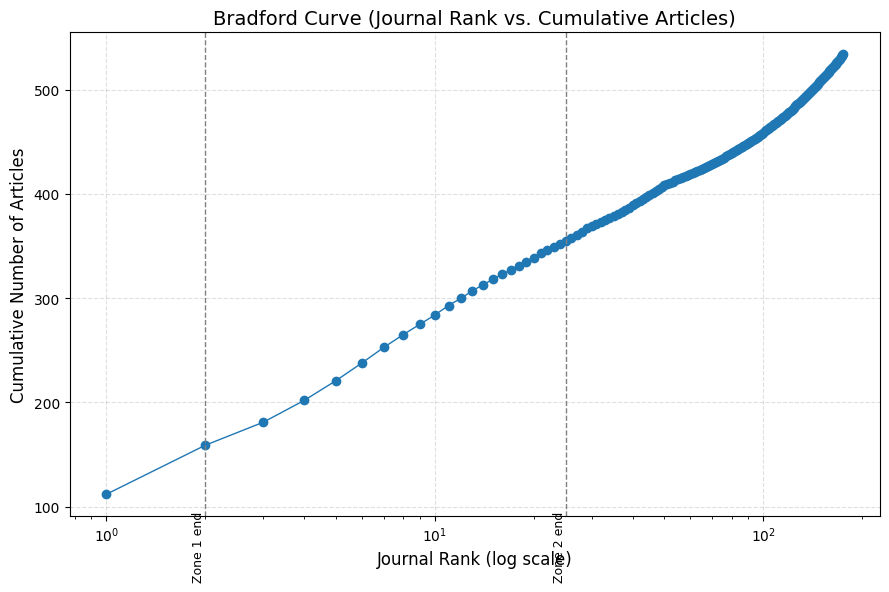

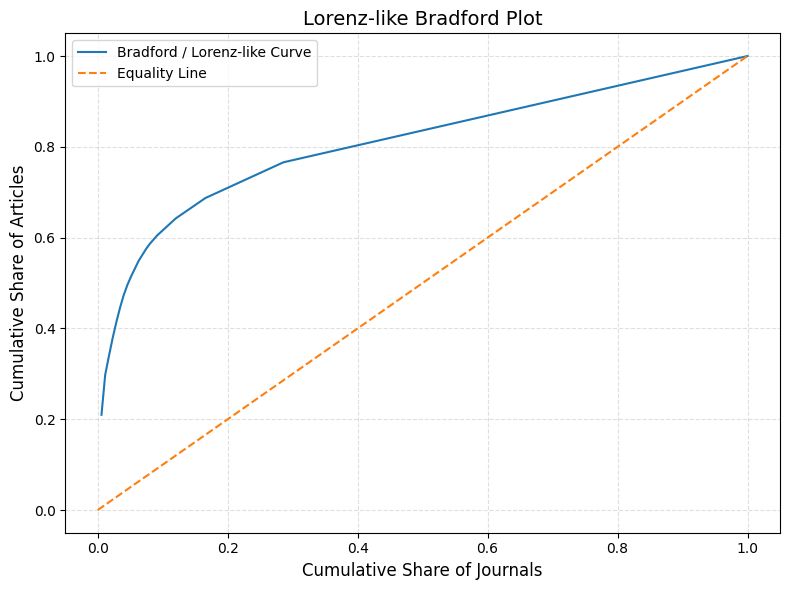

✅ `bradford_zone_distribution_summary.csv` as CSV saved. 
✅ `bradford_journal_details.csv` as CSV saved. 


In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()

df_journal = (
    df.dropna(subset=["journal_title"])
    .groupby("journal_title", as_index=False)
    .size()
    .rename(columns={"size": "Article_Count"})
    .sort_values("Article_Count", ascending=False)
    .reset_index(drop=True)
)

if df_journal.empty:
    raise ValueError("No journal data available for applying Bradford’s Law.")

df_journal["Rank"] = np.arange(1, len(df_journal) + 1)
total_articles = df_journal["Article_Count"].sum()
df_journal["Cumulative_Count"] = df_journal["Article_Count"].cumsum()
df_journal["Cumulative_Share"] = df_journal["Cumulative_Count"] / total_articles

df_journal["Bradford_Zone"] = pd.cut(
    df_journal["Cumulative_Share"],
    bins=[0, 1 / 3, 2 / 3, 1],
    labels=["Zone 1 (Core)", "Zone 2", "Zone 3"],
    include_lowest=True,
)

zone_counts = df_journal["Bradford_Zone"].value_counts().sort_index()
z1 = zone_counts.get("Zone 1 (Core)", 1)
z2 = zone_counts.get("Zone 2", 1)
z3 = zone_counts.get("Zone 3", 1)

b_estimate = np.nanmean([
    z2 / z1 if z1 > 0 else np.nan,
    z3 / z2 if z2 > 0 else np.nan,
])

print("----------------")
print("Bradford’s Law — Results")
print(f"Total Articles: {total_articles}")
print(f"Zone 1 Journals: {z1}, Zone 2: {z2}, Zone 3: {z3}")
print(f"Estimated Bradford Multiplier (b): {b_estimate:.3f}")
print("----------------")

zone_summary = (
    df_journal.groupby("Bradford_Zone", as_index=False, observed=True)
    .agg(
        Journals=("journal_title", "nunique"),
        Articles=("Article_Count", "sum"),
    )
)

zone_summary["Article_Share_%"] = (
    100 * zone_summary["Articles"] / total_articles
).round(2)

plt.figure(figsize=(9, 6))
plt.plot(
    df_journal["Rank"],
    df_journal["Cumulative_Count"],
    marker="o",
    linestyle="-",
    linewidth=1,
)

plt.xscale("log")
plt.xlabel("Journal Rank (log scale)", fontsize=12)
plt.ylabel("Cumulative Number of Articles", fontsize=12)
plt.title("Bradford Curve (Journal Rank vs. Cumulative Articles)", fontsize=14)

zone1_max_rank = df_journal.loc[df_journal["Bradford_Zone"] == "Zone 1 (Core)", "Rank"].max()
zone2_max_rank = df_journal.loc[df_journal["Bradford_Zone"] == "Zone 2", "Rank"].max()

if pd.notna(zone1_max_rank):
    plt.axvline(zone1_max_rank, color="grey", linestyle="--", linewidth=1)
    plt.text(
        zone1_max_rank,
        plt.ylim()[1] * 0.05,
        "Zone 1 end",
        rotation=90,
        va="bottom",
        ha="right",
        fontsize=9,
    )

if pd.notna(zone2_max_rank):
    plt.axvline(zone2_max_rank, color="grey", linestyle="--", linewidth=1)
    plt.text(
        zone2_max_rank,
        plt.ylim()[1] * 0.05,
        "Zone 2 end",
        rotation=90,
        va="bottom",
        ha="right",
        fontsize=9,
    )

plt.grid(True, linestyle="--", alpha=0.4)
plt_savefig(plt, "bradford_curve.png")
plt.show()
plt.close()

df_journal["Cum_Journals"] = df_journal["Rank"]
df_journal["Cum_Journals_Share"] = df_journal["Cum_Journals"] / len(df_journal)

plt.figure(figsize=(8, 6))
plt.plot(
    df_journal["Cum_Journals_Share"],
    df_journal["Cumulative_Share"],
    label="Bradford / Lorenz-like Curve",
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Equality Line")
plt.xlabel("Cumulative Share of Journals", fontsize=12)
plt.ylabel("Cumulative Share of Articles", fontsize=12)
plt.title("Lorenz-like Bradford Plot", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt_savefig(plt, "bradford_lorenz_like_plot.png")
plt.show()
plt.close()

dataframe_to_csv(zone_summary, "bradford_zone_distribution_summary.csv")
dataframe_to_csv(df_journal, "bradford_journal_details.csv")

## Thematic Analysis

### Thematic Category Distribution
Publications were classified into predefined thematic categories to quantify the distribution of research topics across the corpus.

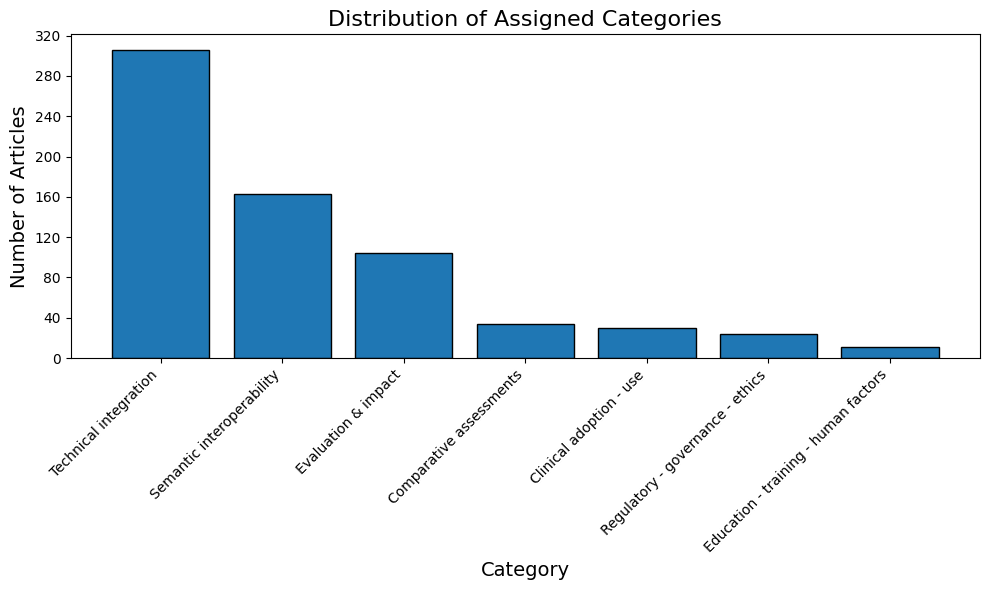

✅ `distribution_of_assigned_categories.csv` as CSV saved. 


In [25]:
import ast

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()


# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


df = df.rename(
    columns={
        "DEFA_assigned_category_v3": "assigned_category",
    }
)

df["assigned_category"] = df["assigned_category"].apply(safe_eval)

category_counts_df = (
    df.explode("assigned_category")
    .dropna(subset=["assigned_category"])
    .assign(assigned_category=lambda x: x["assigned_category"].astype(str).str.strip())
)

category_counts_df = category_counts_df[category_counts_df["assigned_category"] != ""]

category_counts_df = (
    category_counts_df["assigned_category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Count")
)

category_counts_df["Count"] = (
    pd.to_numeric(category_counts_df["Count"], errors="coerce").fillna(0).astype(int)
)

total = category_counts_df["Count"].sum()
category_counts_df["Percent"] = (
    100 * category_counts_df["Count"] / total
).round(2) if total else 0

plt.figure(figsize=(10, 6))
plt.bar(
    category_counts_df["Category"],
    category_counts_df["Count"],
    edgecolor="black",
)
plt.title("Distribution of Assigned Categories", fontsize=16)
plt.xlabel("Category", fontsize=14)
plt.ylabel("Number of Articles", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))
plt.subplots_adjust(bottom=0.25)

plt_savefig(plt, "distribution_of_assigned_categories.png")
plt.show()
plt.close()

dataframe_to_csv(category_counts_df, "distribution_of_assigned_categories.csv")

### Distribution of Research Themes
This analysis presents the proportional representation of each thematic category, identifying dominant and underrepresented research areas.

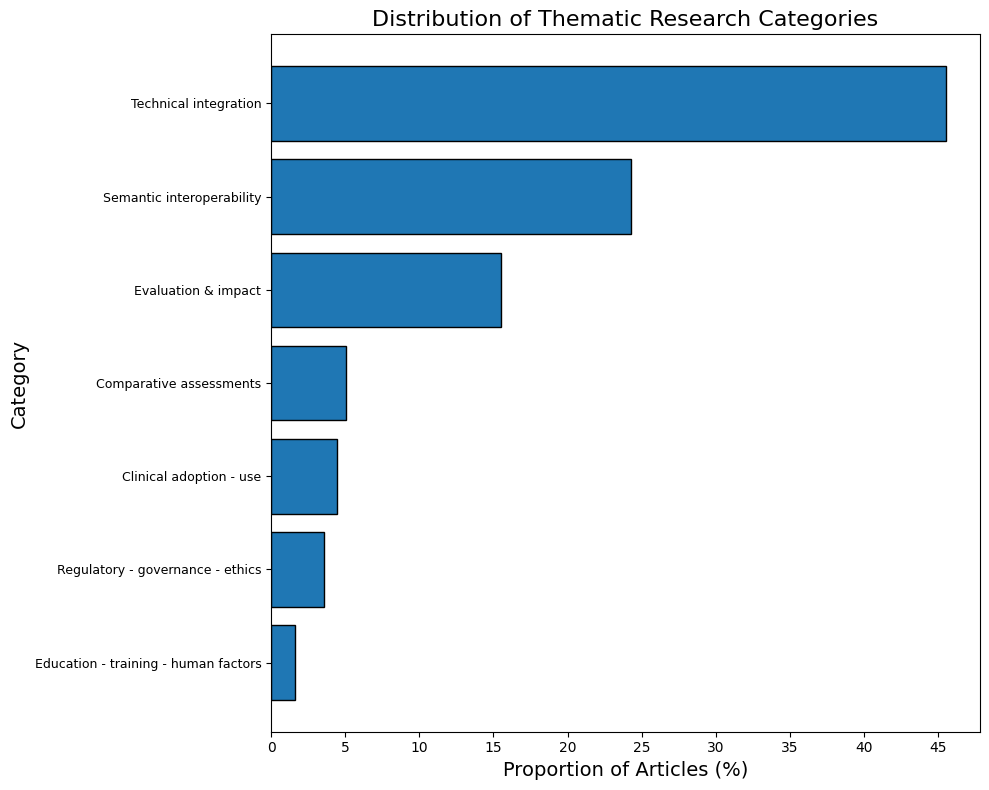

✅ `distribution_of_thematic_research_categories.csv` as CSV saved. 


In [26]:
import ast

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()


# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


df = df.rename(
    columns={
        "DEFA_assigned_category_v3": "assigned_category",
    }
)

df["assigned_category"] = df["assigned_category"].apply(safe_eval)

category_counts_df = (
    df.explode("assigned_category")
    .dropna(subset=["assigned_category"])
    .assign(assigned_category=lambda x: x["assigned_category"].astype(str).str.strip())
)

category_counts_df = category_counts_df[category_counts_df["assigned_category"] != ""]

category_counts_df = (
    category_counts_df["assigned_category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Count")
)

category_counts_df["Count"] = (
    pd.to_numeric(category_counts_df["Count"], errors="coerce").fillna(0).astype(int)
)

total = category_counts_df["Count"].sum()
category_counts_df["Percent"] = (
    100 * category_counts_df["Count"] / total
).round(2) if total else 0.0

category_counts_df = category_counts_df.sort_values("Percent", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 8))
plt.barh(
    category_counts_df["Category"],
    category_counts_df["Percent"],
    edgecolor="black",
)
plt.title("Distribution of Thematic Research Categories", fontsize=16)
plt.xlabel("Proportion of Articles (%)", fontsize=14)
plt.ylabel("Category", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=9)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.gca().invert_yaxis()
plt.subplots_adjust(left=0.3)

plt_savefig(plt, "distribution_of_thematic_research_categories.png")
plt.show()
plt.close()

dataframe_to_csv(
    category_counts_df,
    "distribution_of_thematic_research_categories.csv",
)

### Cross-national Distribution of Research Themes
This section examines how thematic categories are distributed across countries, revealing geographic specialization in research topics.

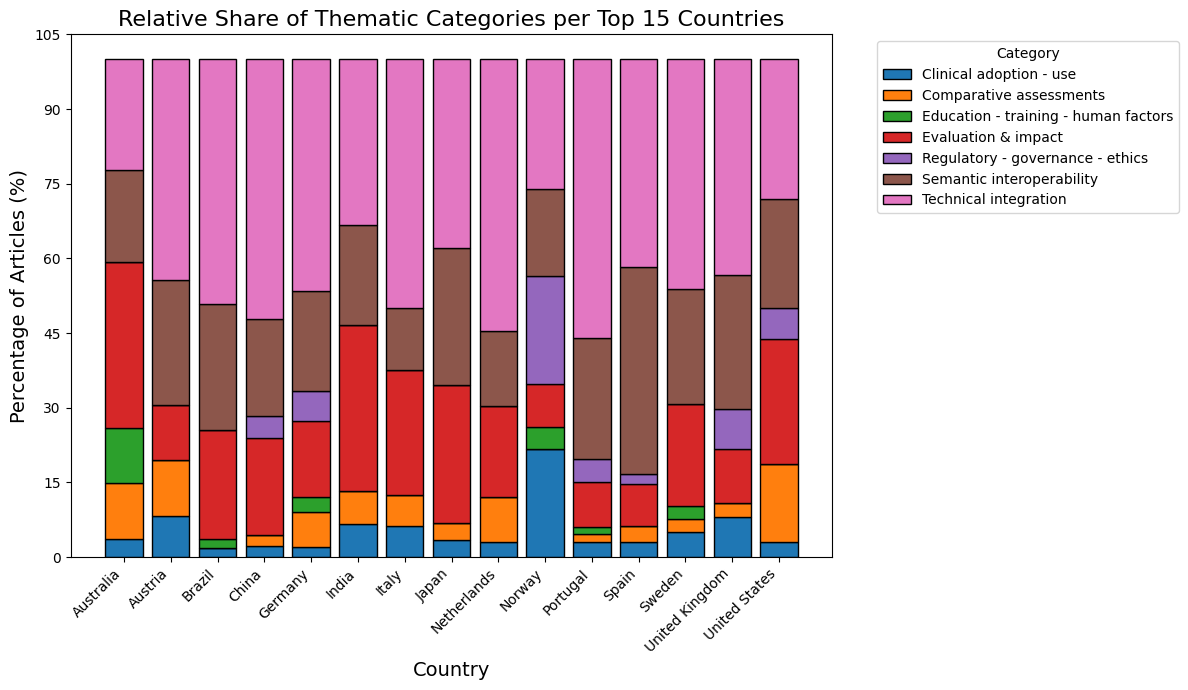

✅ `stacked_thematic_categories_top15_countries.csv` as CSV saved. 


In [27]:
import ast

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

df = DATASET()


# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


df = df.rename(
    columns={
        "DEFA_assigned_category_v3": "assigned_category",
        "affiliation_integration_country": "affiliation_country",
    }
)

df["assigned_category"] = df["assigned_category"].apply(safe_eval)
df["affiliation_country"] = df["affiliation_country"].apply(safe_eval)

df_exp = (
    df.explode("affiliation_country")
    .explode("assigned_category")
    .dropna(subset=["affiliation_country", "assigned_category"])
    .assign(
        affiliation_country=lambda x: x["affiliation_country"].astype(str).str.strip(),
        assigned_category=lambda x: x["assigned_category"].astype(str).str.strip(),
    )
)

df_exp = df_exp[
    (df_exp["affiliation_country"] != "") & (df_exp["assigned_category"] != "")
]

country_category_counts = (
    df_exp.groupby(["affiliation_country", "assigned_category"], as_index=False)
    .size()
    .rename(columns={"size": "Count"})
)

top_countries = (
    country_category_counts.groupby("affiliation_country")["Count"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .index
)

pivot_df = (
    country_category_counts[
        country_category_counts["affiliation_country"].isin(top_countries)
    ]
    .pivot_table(
        index="affiliation_country",
        columns="assigned_category",
        values="Count",
        aggfunc="sum",
        fill_value=0,
    )
)

pivot_pct = (
    pivot_df.div(pivot_df.sum(axis=1), axis=0).mul(100).sort_index()
)

plt.figure(figsize=(12, 7))

bottom = pd.Series(0, index=pivot_pct.index, dtype=float)
for category in pivot_pct.columns:
    plt.bar(
        pivot_pct.index,
        pivot_pct[category],
        bottom=bottom,
        label=category,
        edgecolor="black",
    )
    bottom = bottom + pivot_pct[category]

plt.title("Relative Share of Thematic Categories per Top 15 Countries", fontsize=16)
plt.ylabel("Percentage of Articles (%)", fontsize=14)
plt.xlabel("Country", fontsize=14)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(fontsize=10)
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))
plt.legend(title="Category", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.subplots_adjust(bottom=0.25, right=0.78)

plt_savefig(plt, "stacked_thematic_categories_top15_countries.png")
plt.show()
plt.close()

dataframe_to_csv(
    pivot_pct.reset_index(),
    "stacked_thematic_categories_top15_countries.csv",
)

### Temporal Evolution of Thematic Diversity (Shannon Index) 
To quantify the thematic diversity within the corpus of research articles, we employed the **Shannon Diversity Index (H′)**, a widely used information-theoretic measure of heterogeneity across categorical distributions. This index captures both **richness** (the number of distinct thematic categories) and **evenness** (the balance in their relative frequencies). Higher values of *H′* indicate a more diverse and evenly distributed thematic landscape, whereas lower values reflect concentration around a few dominant themes.

The Shannon Index is calculated using the standard formulation:

$$
H' = -\sum_{i=1}^{S} p_i , \ln(p_i)
$$

where:

* ( S ) is the total number of thematic categories observed,
* ( p_i ) is the proportion of all category assignments belonging to category ( i ),
* ( p_i \ln(p_i) ) is defined only for ( p_i > 0 ) to avoid logarithmic singularities.

This measure is particularly appropriate for thematic analysis because it does not assume uniform category sizes, is sensitive to changes in both common and rare categories, and provides a continuous, interpretable scale for comparing thematic diversity across different years, countries, or publication sets.

Overall Shannon Index for thematic categories: 1.467


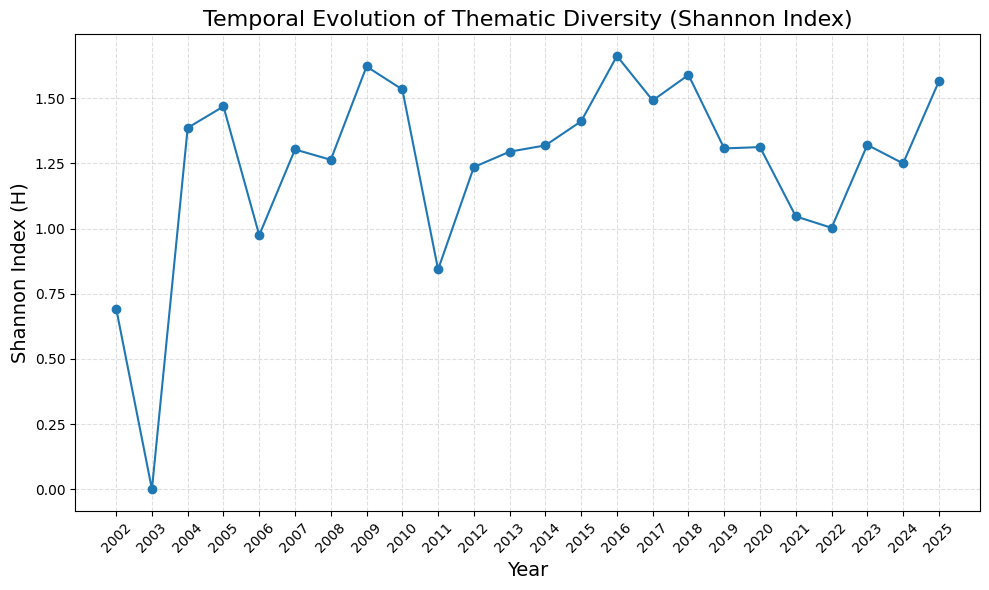

✅ `shannon_thematic_diversity_over_time.csv` as CSV saved. 


In [28]:
import ast

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

YEAR_MIN = None
YEAR_MAX = None

df = DATASET()


# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


def shannon_index(counts):
    total = counts.sum()
    if total == 0:
        return 0.0
    proportions = counts / total
    proportions = proportions[proportions > 0]
    return float(-(proportions * np.log(proportions)).sum())


df = df.rename(
    columns={
        "DEFA_assigned_category_v3": "assigned_category",
    }
)

df["assigned_category"] = df["assigned_category"].apply(safe_eval)
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)

if YEAR_MIN is not None:
    df = df[df["year"] >= YEAR_MIN]
if YEAR_MAX is not None:
    df = df[df["year"] <= YEAR_MAX]

if df.empty:
    raise ValueError("No articles available after year filtering for Shannon diversity analysis.")

df_exploded = (
    df.explode("assigned_category")
    .dropna(subset=["assigned_category"])
    .assign(assigned_category=lambda x: x["assigned_category"].astype(str).str.strip())
)

df_exploded = df_exploded[df_exploded["assigned_category"] != ""]

if df_exploded.empty:
    raise ValueError("No thematic categories found in assigned_category after exploding.")

overall_shannon = shannon_index(df_exploded["assigned_category"].value_counts())
print(f"Overall Shannon Index for thematic categories: {overall_shannon:.3f}")

shannon_df = (
    df_exploded.groupby("year")["assigned_category"]
    .value_counts()
    .groupby(level=0)
    .apply(shannon_index)
    .reset_index(name="Shannon_Index")
    .rename(columns={"year": "Year"})
    .sort_values("Year")
    .reset_index(drop=True)
)

plt.figure(figsize=(10, 6))
plt.plot(
    shannon_df["Year"],
    shannon_df["Shannon_Index"],
    marker="o",
)
plt.title("Temporal Evolution of Thematic Diversity (Shannon Index)", fontsize=16)
plt.xlabel("Year", fontsize=14)
plt.ylabel("Shannon Index (H)", fontsize=14)
plt.xticks(shannon_df["Year"], rotation=45)
plt.grid(True, linestyle="--", alpha=0.4)
plt.subplots_adjust(bottom=0.2)

plt_savefig(plt, "shannon_thematic_diversity_over_time.png")
plt.show()
plt.close()

dataframe_to_csv(
    shannon_df,
    "shannon_thematic_diversity_over_time.csv",
)

### Thematic Evolution Sankey Diagram 
A Sankey diagram was used to visualize the continuity of major thematic categories across consecutive time periods. For each period, publication counts were aggregated by thematic category, and flows between adjacent periods were defined based on the shared presence of the same category. Flow magnitude was conservatively estimated using the minimum count observed across the two connected periods. This visualization highlights the persistence and changing prominence of thematic domains over time.

In [29]:
import ast
import pandas as pd
import plotly.graph_objects as go
from src.config import OUTPUT_DIR
from src.lib_dataset import DATASET
from src.lib_visualization import dataframe_to_csv

# ---------------------- Settings -------------------------
YEAR_MIN = 2002
YEAR_MAX = 2025
TOP_N_CATEGORIES = 3
OTHER_LABEL = "Other"

PERIODS = [
    ("2002-2007", 2002, 2007),
    ("2008-2013", 2008, 2013),
    ("2014-2019", 2014, 2019),
    ("2020-2025", 2020, 2025),
]

df = DATASET()

# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]

def assign_period(year):
    for label, start, end in PERIODS:
        if start <= year <= end:
            return label
    return None

def make_node_label(period, category, count):
    return f"{period} | {category} ({count})"

# ---------------------- Main use -------------------------

df["assigned_category"] = df["assigned_category"].apply(safe_eval)
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)
df = df[(df["year"] >= YEAR_MIN) & (df["year"] <= YEAR_MAX)].copy()

if df.empty:
    raise ValueError("No articles found in the specified year range.")

df["Period"] = df["year"].apply(assign_period)
df = df.dropna(subset=["Period"]).copy()

# Explode thematic categories
df_exploded = (
    df[["DBUID", "Period", "assigned_category"]]
    .explode("assigned_category")
    .dropna(subset=["assigned_category"])
    .copy()
)

df_exploded["assigned_category"] = df_exploded["assigned_category"].astype(str).str.strip()
df_exploded = df_exploded[df_exploded["assigned_category"] != ""]

if df_exploded.empty:
    raise ValueError("No thematic category data available after exploding assigned_category.")

# Keep top global categories and collapse the rest
top_categories = (
    df_exploded["assigned_category"]
    .value_counts()
    .head(TOP_N_CATEGORIES)
    .index
    .tolist()
)

df_exploded["Category_Grouped"] = df_exploded["assigned_category"].apply(
    lambda x: x if x in top_categories else OTHER_LABEL
)

# Count unique articles per period and category
period_theme_counts = (
    df_exploded.groupby(["Period", "Category_Grouped"], as_index=False)
    .agg(Count=("DBUID", "nunique"))
)

# Create full matrix to preserve zero cells
period_order = [p[0] for p in PERIODS]
all_categories = sorted(period_theme_counts["Category_Grouped"].dropna().unique().tolist())

full_index = pd.MultiIndex.from_product(
    [period_order, all_categories],
    names=["Period", "Category_Grouped"]
)

period_theme_counts = (
    period_theme_counts
    .set_index(["Period", "Category_Grouped"])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

dataframe_to_csv(period_theme_counts, "thematic_counts_by_period.csv")

# Node label dictionary
node_label_map = {}
for _, row in period_theme_counts.iterrows():
    period = row["Period"]
    category = row["Category_Grouped"]
    count = int(row["Count"])
    node_label_map[(period, category)] = make_node_label(period, category, count)

# Build continuity flows only
flow_rows = []

for i in range(len(period_order) - 1):
    period_a = period_order[i]
    period_b = period_order[i + 1]

    df_a = (
        period_theme_counts[period_theme_counts["Period"] == period_a]
        .rename(columns={"Category_Grouped": "Category", "Count": "Count_A"})
        [["Category", "Count_A"]]
    )

    df_b = (
        period_theme_counts[period_theme_counts["Period"] == period_b]
        .rename(columns={"Category_Grouped": "Category", "Count": "Count_B"})
        [["Category", "Count_B"]]
    )

    merged = df_a.merge(df_b, on="Category", how="outer").fillna(0)

    for _, row in merged.iterrows():
        category = row["Category"]
        count_a = int(row["Count_A"])
        count_b = int(row["Count_B"])
        flow_value = min(count_a, count_b)

        if flow_value <= 0:
            continue

        flow_rows.append({
            "Source_Period": period_a,
            "Target_Period": period_b,
            "Category": category,
            "Source_Count": count_a,
            "Target_Count": count_b,
            "Flow": flow_value,
            "Source_Label": node_label_map[(period_a, category)],
            "Target_Label": node_label_map[(period_b, category)],
        })

flows_df = pd.DataFrame(flow_rows)

if flows_df.empty:
    raise ValueError("No thematic continuity flows were created for Sankey visualization.")

dataframe_to_csv(flows_df, "thematic_evolution_sankey_continuity_flows.csv")

# Keep only connected nodes
used_nodes = pd.unique(
    pd.concat([flows_df["Source_Label"], flows_df["Target_Label"]], ignore_index=True)
).tolist()

node_map = {label: idx for idx, label in enumerate(used_nodes)}

sources = flows_df["Source_Label"].map(node_map).tolist()
targets = flows_df["Target_Label"].map(node_map).tolist()
values = flows_df["Flow"].astype(int).tolist()

# Plot
fig = go.Figure(
    data=[
        go.Sankey(
            arrangement="snap",
            node=dict(
                pad=18,
                thickness=18,
                line=dict(color="black", width=0.5),
                label=used_nodes,
            ),
            link=dict(
                source=sources,
                target=targets,
                value=values,
            ),
        )
    ]
)

fig.update_layout(
    title={
        "text": "Thematic Evolution Flow Across Time Periods",
        "x": 0.5,
    },
    font=dict(size=11),
)

# Save outputs 
html_path = OUTPUT_DIR / "thematic_evolution_sankey_labeled_counts.html"
fig.write_html(str(html_path))
print("Saved HTML: thematic_evolution_sankey_labeled_counts.html")

try:
    fig.write_image(
        str(OUTPUT_DIR / "thematic_evolution_sankey_labeled_counts.png"),
        format="png",
        scale=2,
    )
    print("Saved PNG: thematic_evolution_sankey_labeled_counts.png")
except Exception as e:
    print(f"Could not save PNG (Plotly static export error): {e}")

fig.show()

✅ `thematic_counts_by_period.csv` as CSV saved. 
✅ `thematic_evolution_sankey_continuity_flows.csv` as CSV saved. 
Saved HTML: thematic_evolution_sankey_labeled_counts.html
Could not save PNG (Plotly static export error): 
Image export using the "kaleido" engine requires the Kaleido package,
which can be installed using pip:

    $ pip install --upgrade kaleido



### Thematic Strategic Diagram (Category-Based)
A category-based thematic strategic diagram was constructed using the predefined thematic classification of the corpus. Centrality was estimated from the weighted co-occurrence of each category with other thematic domains, whereas density was approximated by the average strength of its observed thematic links. Categories were then positioned into four quadrants representing motor themes, basic themes, niche themes, and emerging or declining themes. This visualization provides a structured overview of the relative maturity and interconnectedness of the thematic domains identified in the study.

✅ `strategic_diagram_category_frequency.csv` as CSV saved. 
✅ `strategic_diagram_category_edges.csv` as CSV saved. 
✅ `thematic_strategic_diagram_category_based_metrics.csv` as CSV saved. 


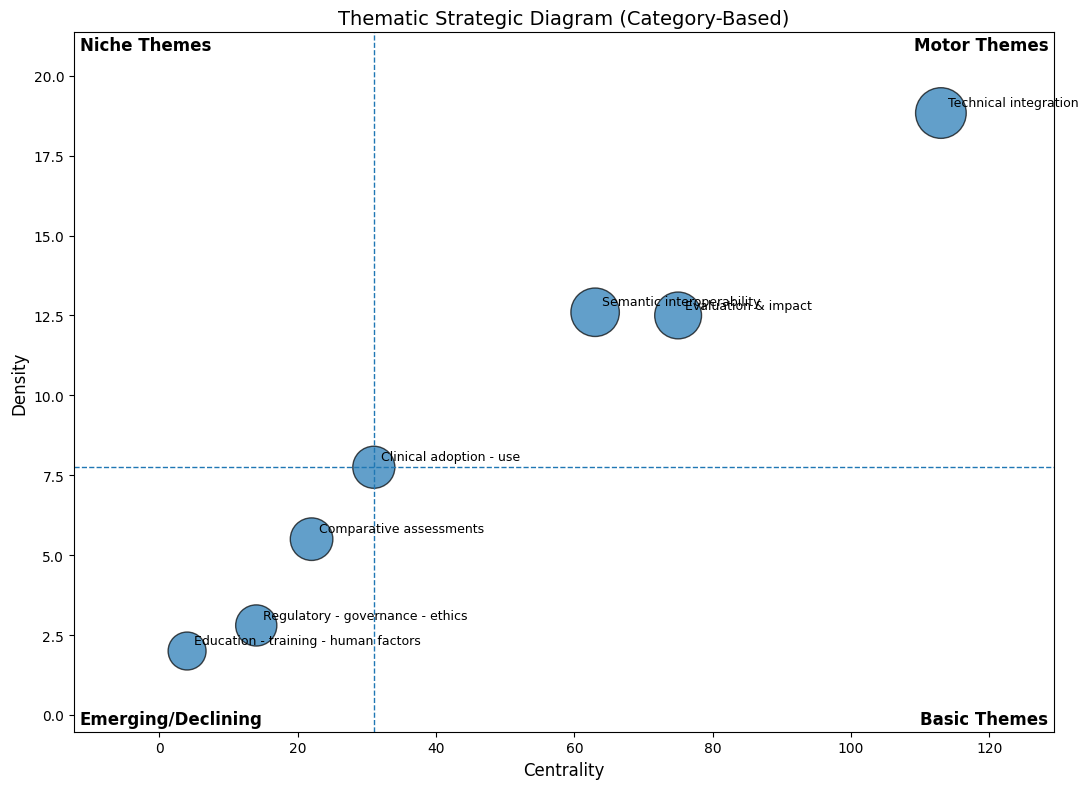

Median centrality: 31.0
Median density: 7.75
Number of thematic categories plotted: 7


In [30]:
import ast
import math
import itertools
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

# ---------------------- Settings -------------------------
MIN_CATEGORY_FREQ = 5
MIN_EDGE_WEIGHT = 2

df = DATASET()

# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]

def clean_text_list(values):
    cleaned = []
    for value in values:
        if pd.isna(value):
            continue
        text = str(value).strip()
        if text == "":
            continue
        cleaned.append(text)
    return cleaned

def deduplicate_preserve_order(values):
    seen = set()
    result = []
    for value in values:
        if value not in seen:
            seen.add(value)
            result.append(value)
    return result

# Load and clean 
CATEGORY_COL = "assigned_category"

if CATEGORY_COL not in df.columns:
    raise ValueError(f"Column '{CATEGORY_COL}' is required for category-based strategic diagram.")

df["thematic_categories"] = df[CATEGORY_COL].apply(safe_eval)
df["thematic_categories"] = df["thematic_categories"].apply(clean_text_list)
df["thematic_categories"] = df["thematic_categories"].apply(deduplicate_preserve_order)

df = df[df["thematic_categories"].apply(len) > 0].copy()

if df.empty:
    raise ValueError("No valid thematic category data found after preprocessing.")

# Category frequency
category_freq = (
    df.explode("thematic_categories")["thematic_categories"]
    .value_counts()
    .reset_index()
)
category_freq.columns = ["Category", "Frequency"]

category_freq = category_freq[category_freq["Frequency"] >= MIN_CATEGORY_FREQ].copy()

if category_freq.empty:
    raise ValueError("No thematic categories remained after frequency filtering.")

selected_categories = set(category_freq["Category"].tolist())

dataframe_to_csv(category_freq, "strategic_diagram_category_frequency.csv")

# Build category co-occurrence edges
edge_counter = {}

for _, row in df.iterrows():
    cats = [c for c in row["thematic_categories"] if c in selected_categories]
    cats = sorted(set(cats))

    if len(cats) < 2:
        continue

    for a, b in itertools.combinations(cats, 2):
        edge_counter[(a, b)] = edge_counter.get((a, b), 0) + 1

edge_rows = [
    {"Source": a, "Target": b, "Weight": w}
    for (a, b), w in edge_counter.items()
    if w >= MIN_EDGE_WEIGHT
]

edge_df = pd.DataFrame(edge_rows)

if edge_df.empty:
    raise ValueError(
        "No category co-occurrence edges remained after filtering. "
        "Try lowering MIN_EDGE_WEIGHT."
    )

dataframe_to_csv(edge_df, "strategic_diagram_category_edges.csv")

# Build graph
G = nx.Graph()

for _, row in category_freq.iterrows():
    G.add_node(row["Category"], frequency=int(row["Frequency"]))

for _, row in edge_df.iterrows():
    G.add_edge(row["Source"], row["Target"], weight=float(row["Weight"]))

isolates = list(nx.isolates(G))
if isolates:
    G.remove_nodes_from(isolates)

if G.number_of_nodes() < 3:
    raise ValueError("Too few connected thematic categories are available for the strategic diagram.")

# Compute category-level metrics
rows = []

for node in G.nodes():
    node_frequency = G.nodes[node].get("frequency", 0)

    neighbors = list(G.neighbors(node))
    weighted_degree = sum(G[node][nbr].get("weight", 0.0) for nbr in neighbors)

    # Centrality: weighted external connectivity to the thematic network
    centrality = weighted_degree

    # Density proxy: average strength of links for this thematic category
    density = weighted_degree / len(neighbors) if len(neighbors) > 0 else 0.0

    rows.append({
        "Category": node,
        "Frequency": int(node_frequency),
        "Num_Neighbors": int(len(neighbors)),
        "Weighted_Degree": float(weighted_degree),
        "Centrality": float(centrality),
        "Density": float(density),
    })

theme_df = pd.DataFrame(rows)

if theme_df.empty:
    raise ValueError("No strategic diagram metrics could be computed.")

theme_df = theme_df.sort_values(
    ["Frequency", "Weighted_Degree"],
    ascending=[False, False]
).reset_index(drop=True)

# Quadrants
median_centrality = theme_df["Centrality"].median()
median_density = theme_df["Density"].median()

def assign_quadrant(row, x_med, y_med):
    x = row["Centrality"]
    y = row["Density"]

    if x >= x_med and y >= y_med:
        return "Motor Themes"
    elif x >= x_med and y < y_med:
        return "Basic Themes"
    elif x < x_med and y >= y_med:
        return "Niche Themes"
    else:
        return "Emerging/Declining Themes"

theme_df["Quadrant"] = theme_df.apply(
    lambda row: assign_quadrant(row, median_centrality, median_density),
    axis=1
)

dataframe_to_csv(theme_df, "thematic_strategic_diagram_category_based_metrics.csv")

# Plot
plt.figure(figsize=(11, 8))

sizes = [
    300 + 180 * math.log1p(v)
    for v in theme_df["Frequency"].astype(float).tolist()
]

plt.scatter(
    theme_df["Centrality"],
    theme_df["Density"],
    s=sizes,
    alpha=0.7,
    edgecolors="black",
    linewidths=1,
)

for _, row in theme_df.iterrows():
    plt.annotate(
        row["Category"],
        (row["Centrality"], row["Density"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
    )

plt.axvline(x=median_centrality, linestyle="--", linewidth=1)
plt.axhline(y=median_density, linestyle="--", linewidth=1)

x_min = theme_df["Centrality"].min()
x_max = theme_df["Centrality"].max()
y_min = theme_df["Density"].min()
y_max = theme_df["Density"].max()

x_pad = (x_max - x_min) * 0.15 if x_max > x_min else 1.0
y_pad = (y_max - y_min) * 0.15 if y_max > y_min else 1.0

plt.xlim(x_min - x_pad, x_max + x_pad)
plt.ylim(y_min - y_pad, y_max + y_pad)

plt.text(
    x_max + x_pad * 0.95, y_max + y_pad * 0.95, "Motor Themes",
    ha="right", va="top", fontsize=12, fontweight="bold"
)
plt.text(
    x_max + x_pad * 0.95, y_min - y_pad * 0.95, "Basic Themes",
    ha="right", va="bottom", fontsize=12, fontweight="bold"
)
plt.text(
    x_min - x_pad * 0.95, y_max + y_pad * 0.95, "Niche Themes",
    ha="left", va="top", fontsize=12, fontweight="bold"
)
plt.text(
    x_min - x_pad * 0.95, y_min - y_pad * 0.95, "Emerging/Declining",
    ha="left", va="bottom", fontsize=12, fontweight="bold"
)

plt.xlabel("Centrality", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.title("Thematic Strategic Diagram (Category-Based)", fontsize=14)
plt.tight_layout()

plt_savefig(plt, "thematic_strategic_diagram_category_based.png")
plt.show()
plt.close()

print("Median centrality:", round(median_centrality, 4))
print("Median density:", round(median_density, 4))
print("Number of thematic categories plotted:", len(theme_df))

The category-based thematic strategic diagram reveals a clear structural hierarchy within the research field. Technical integration is positioned as a dominant motor theme, exhibiting both high centrality and density, indicating that it is both well-developed and strongly interconnected with other domains. Semantic interoperability and evaluation & impact also occupy the upper-right quadrant, suggesting that these areas are mature and play a central role in shaping the field’s knowledge structure. In contrast, clinical adoption – use appears near the boundary between basic and emerging themes, reflecting moderate integration but comparatively lower internal cohesion, consistent with its limited representation in the literature. Themes such as regulatory, governance, and ethics and education, training, and human factors fall within the emerging or declining quadrant, indicating weak connectivity and low development, and highlighting critical gaps in non-technical dimensions. Overall, the diagram confirms a strong concentration of research around technical and interoperability-oriented topics, with underdeveloped attention to governance, human factors, and real-world clinical implementation.

### Temporal Trends of High-Frequency Keywords
A bubble chart was used to visualize temporal trends of high-frequency keywords. Each bubble represents the normalized frequency of a keyword in a given year, with bubble size proportional to its relative occurrence. This visualization enables intuitive identification of emerging, stable, and declining thematic trends over time.

✅ `temporal_keyword_trends_bubble.csv` as CSV saved. 


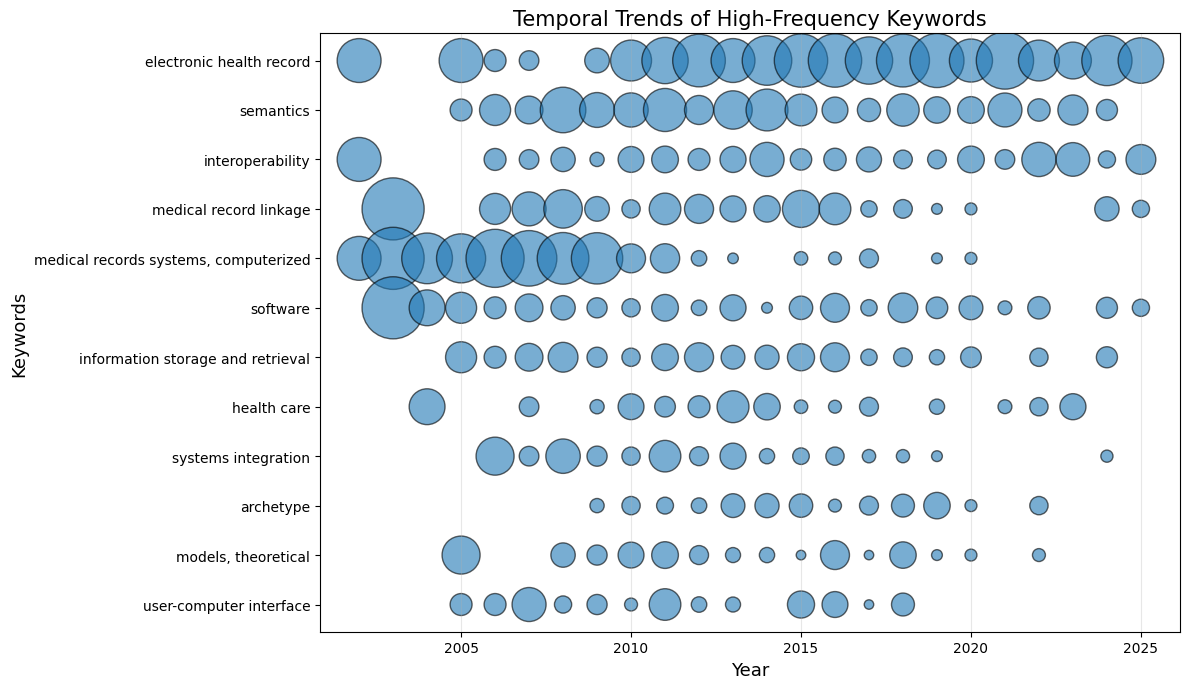

In [31]:
import ast
import pandas as pd
import matplotlib.pyplot as plt

from src.lib_dataset import DATASET, keyword_map, unwanted_keywords
from src.lib_visualization import plt_savefig, dataframe_to_csv

# ---------------------- Settings -------------------------
TOP_N_KEYWORDS = 12
YEAR_MIN = 2002
YEAR_MAX = 2025

df = DATASET()

# Helper
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return []
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except:
        return []

def clean_keywords(values):
    cleaned = []

    for value in values:
        if pd.isna(value):
            continue

        keyword = str(value).strip()
        if keyword == "":
            continue

        keyword_lower = keyword.lower()

        # remove unwanted
        if keyword_lower in unwanted_keywords():
            continue

        # normalize
        keyword_normalized = keyword_map().get(keyword_lower, keyword_lower).strip()

        if keyword_normalized in unwanted_keywords():
            continue

        cleaned.append(keyword_normalized)

    return list(dict.fromkeys(cleaned))

# Load
df["keywords"] = df["keywords"].apply(safe_eval).apply(clean_keywords)

df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)

df = df[(df["year"] >= YEAR_MIN) & (df["year"] <= YEAR_MAX)]
df = df[df["keywords"].apply(len) > 0]

# Top keywords
keyword_freq = (
    df.explode("keywords")["keywords"]
    .value_counts()
    .head(TOP_N_KEYWORDS)
)

top_keywords = keyword_freq.index.tolist()

# Build dataset
records = []

for year in sorted(df["year"].unique()):
    df_year = df[df["year"] == year]
    total_articles = len(df_year)

    counts = df_year.explode("keywords")["keywords"].value_counts()

    for kw in top_keywords:
        count = counts.get(kw, 0)

        if count == 0:
            continue

        normalized = count / total_articles

        records.append({
            "Year": year,
            "Keyword": kw,
            "Count": count,
            "Normalized": normalized
        })

trend_df = pd.DataFrame(records)

dataframe_to_csv(trend_df, "temporal_keyword_trends_bubble.csv")

# Bubble Plot
plt.figure(figsize=(12, 7))

# map keywords to y-axis positions
keyword_order = list(reversed(top_keywords))
y_map = {kw: i for i, kw in enumerate(keyword_order)}

x = trend_df["Year"]
y = trend_df["Keyword"].map(y_map)

# bubble size (خیلی مهم برای زیبایی)
sizes = trend_df["Normalized"] * 2000  # adjust scale if needed

plt.scatter(
    x,
    y,
    s=sizes,
    alpha=0.6,
    edgecolors="black"
)

# y labels
plt.yticks(
    list(y_map.values()),
    keyword_order
)

plt.xlabel("Year", fontsize=13)
plt.ylabel("Keywords", fontsize=13)
plt.title("Temporal Trends of High-Frequency Keywords", fontsize=15)

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt_savefig(plt, "temporal_keyword_trends_bubble.png")

plt.show()
plt.close()

### Temporal Trends of Top Growing Keywords
To identify emerging conceptual trends, keywords were ranked according to the slope of their normalized yearly frequencies over time. After keyword normalization and filtering, annual keyword frequencies were divided by the total number of publications in each year, and a linear trend was fitted for each keyword across the study period. The highest-ranking positively sloped keywords were then visualized using a bubble chart, where bubble size represents normalized yearly prominence.

✅ `keyword_year_normalized_frequencies_all.csv` as CSV saved. 
✅ `keyword_growth_statistics.csv` as CSV saved. 
✅ `top_growing_keywords.csv` as CSV saved. 
✅ `temporal_top_growing_keywords_bubble.csv` as CSV saved. 


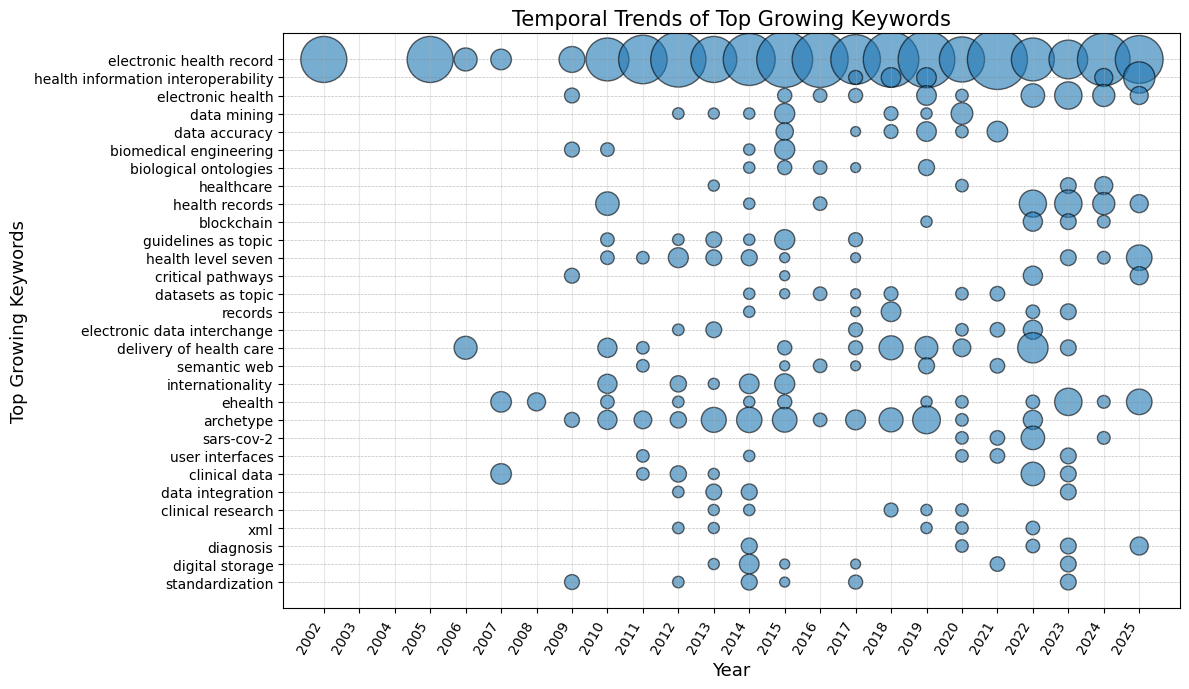

The keyword with the strongest positive temporal growth was 'electronic health record', with a slope of 0.013918 in normalized yearly frequency.


In [32]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.lib_dataset import DATASET, keyword_map, unwanted_keywords
from src.lib_visualization import plt_savefig, dataframe_to_csv

# ---------------------- Settings -------------------------
TOP_N_GROWING_KEYWORDS = 30
MIN_TOTAL_FREQ = 5
MIN_YEARS_PRESENT = 4
YEAR_MIN = 2002
YEAR_MAX = 2025
BUBBLE_SCALE = 2200

df = DATASET()

# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return []
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except:
        return []

def clean_keywords(values):
    cleaned = []

    for value in values:
        if pd.isna(value):
            continue

        keyword = str(value).strip()
        if keyword == "":
            continue

        keyword_lower = keyword.lower()

        if keyword_lower in unwanted_keywords():
            continue

        keyword_normalized = keyword_map().get(keyword_lower, keyword_lower).strip()

        if keyword_normalized == "":
            continue

        if keyword_normalized in unwanted_keywords():
            continue

        cleaned.append(keyword_normalized)

    return list(dict.fromkeys(cleaned))

# Load and clean
if "keywords" not in df.columns:
    raise ValueError("Column 'keywords' is required.")

df["keywords"] = df["keywords"].apply(safe_eval).apply(clean_keywords)

df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)

df = df[(df["year"] >= YEAR_MIN) & (df["year"] <= YEAR_MAX)].copy()
df = df[df["keywords"].apply(len) > 0].copy()

if df.empty:
    raise ValueError("No valid data remained after preprocessing.")

# Yearly totals
yearly_totals = (
    df.groupby("year", as_index=False)
    .agg(Total_Articles=("DBUID", "count"))
    .sort_values("year")
    .reset_index(drop=True)
)

# Keyword-year normalized frequencies
records = []

for year in sorted(df["year"].unique()):
    df_year = df[df["year"] == year].copy()
    total_articles = len(df_year)

    counts = df_year.explode("keywords")["keywords"].value_counts()

    for keyword, count in counts.items():
        records.append({
            "Year": int(year),
            "Keyword": keyword,
            "Count": int(count),
            "Normalized_Frequency": count / total_articles
        })

trend_df = pd.DataFrame(records)

if trend_df.empty:
    raise ValueError("No keyword trend data could be generated.")

dataframe_to_csv(trend_df, "keyword_year_normalized_frequencies_all.csv")

# Compute growth slopes
growth_rows = []

for keyword, subset in trend_df.groupby("Keyword"):
    subset = subset.sort_values("Year").copy()

    total_freq = int(subset["Count"].sum())
    years_present = int((subset["Count"] > 0).sum())

    if total_freq < MIN_TOTAL_FREQ:
        continue

    if years_present < MIN_YEARS_PRESENT:
        continue

    x = subset["Year"].to_numpy()
    y = subset["Normalized_Frequency"].to_numpy()

    if len(x) < 2:
        continue

    slope, intercept = np.polyfit(x, y, 1)

    growth_rows.append({
        "Keyword": keyword,
        "Total_Count": total_freq,
        "Years_Present": years_present,
        "Slope": float(slope),
        "Intercept": float(intercept),
        "Max_Normalized_Frequency": float(subset["Normalized_Frequency"].max()),
        "Mean_Normalized_Frequency": float(subset["Normalized_Frequency"].mean()),
    })

growth_df = pd.DataFrame(growth_rows)

if growth_df.empty:
    raise ValueError("No keyword growth statistics could be computed.")

growth_df = growth_df.sort_values(
    ["Slope", "Total_Count"],
    ascending=[False, False]
).reset_index(drop=True)

dataframe_to_csv(growth_df, "keyword_growth_statistics.csv")

# Select top growing keywords
top_growing_df = growth_df[growth_df["Slope"] > 0].head(TOP_N_GROWING_KEYWORDS).copy()

if top_growing_df.empty:
    raise ValueError("No positively growing keywords were identified.")

top_keywords = top_growing_df["Keyword"].tolist()

dataframe_to_csv(top_growing_df, "top_growing_keywords.csv")

# Keep selected keywords for plotting
plot_df = trend_df[trend_df["Keyword"].isin(top_keywords)].copy()

# Add missing year-keyword pairs as zero for visual continuity
all_years = sorted(df["year"].unique())
full_index = pd.MultiIndex.from_product(
    [all_years, top_keywords],
    names=["Year", "Keyword"]
)

plot_df = (
    plot_df.set_index(["Year", "Keyword"])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

dataframe_to_csv(plot_df, "temporal_top_growing_keywords_bubble.csv")

# Bubble plot
plt.figure(figsize=(12, 7))

keyword_order = top_growing_df.sort_values("Slope", ascending=True)["Keyword"].tolist()
y_map = {kw: i for i, kw in enumerate(keyword_order)}

x = plot_df["Year"]
y = plot_df["Keyword"].map(y_map)
sizes = plot_df["Normalized_Frequency"] * BUBBLE_SCALE

plt.scatter(
    x,
    y,
    s=sizes,
    alpha=0.6,
    edgecolors="black"
)

for y_pos in y_map.values():
    plt.axhline(y=y_pos, color='gray', linestyle='--', linewidth=0.5, alpha=0.5)

plt.yticks(list(y_map.values()), keyword_order)
plt.xlabel("Year", fontsize=13)
plt.ylabel("Top Growing Keywords", fontsize=13)
plt.title("Temporal Trends of Top Growing Keywords", fontsize=15)
plt.xticks(all_years, rotation=60, ha="right")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt_savefig(plt, "temporal_top_growing_keywords_bubble.png")

plt.show()
plt.close()

# Result
top_row = top_growing_df.iloc[0]
print(
    f"The keyword with the strongest positive temporal growth was '{top_row['Keyword']}', "
    f"with a slope of {top_row['Slope']:.6f} in normalized yearly frequency."
)

### Decomposition of Thematic Diversity (Richness and Evenness)
To further interpret thematic diversity, the Shannon index was decomposed into richness and evenness components. Richness was defined as the number of distinct thematic categories observed in each year, while evenness was calculated as the normalized Shannon index, reflecting the balance of thematic distribution. This decomposition enables a more nuanced understanding of whether increases in diversity are driven by the expansion of thematic scope or by a more even distribution of research efforts across existing themes.


✅ `thematic_diversity_decomposition.csv` as CSV saved. 


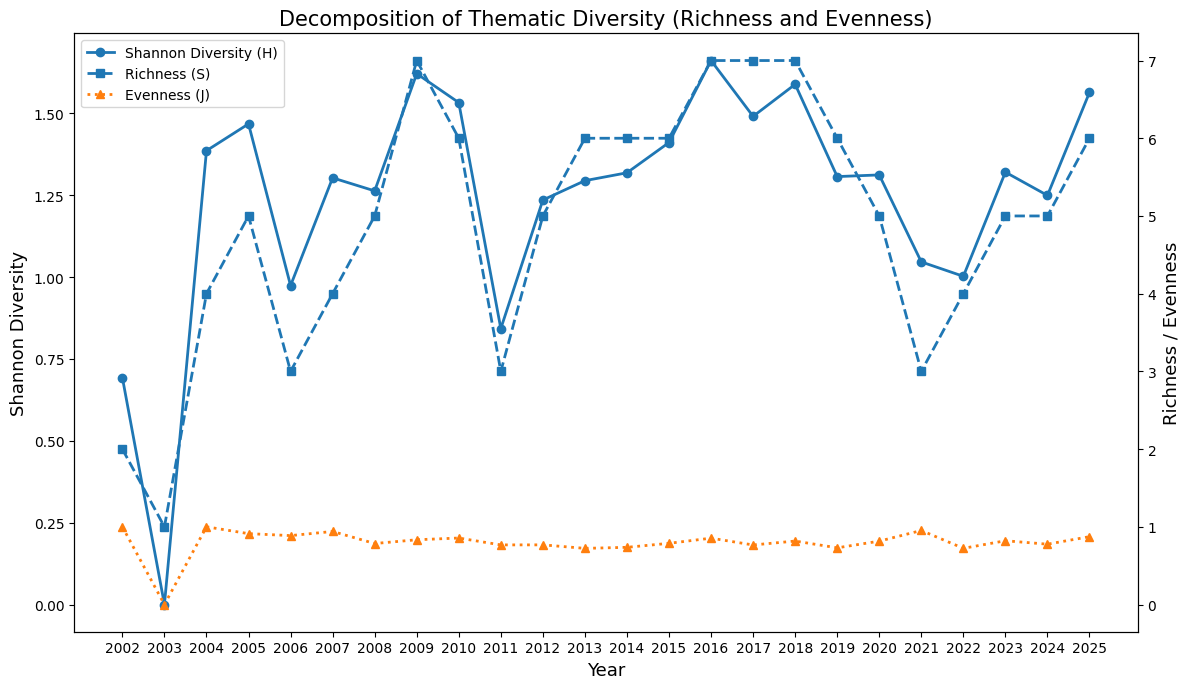

In [33]:
import ast
import math
import pandas as pd
import matplotlib.pyplot as plt

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

# ---------------------- Settings -------------------------
YEAR_MIN = 2002
YEAR_MAX = 2025

CATEGORY_COL = "assigned_category"

df = DATASET()

# Helper
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return []
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except:
        return []

def clean(values):
    return list(dict.fromkeys([
        str(v).strip()
        for v in values
        if pd.notna(v) and str(v).strip() != ""
    ]))

# Load
if CATEGORY_COL not in df.columns:
    raise ValueError(f"Column '{CATEGORY_COL}' is required.")

df["categories"] = df[CATEGORY_COL].apply(safe_eval).apply(clean)

df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year"]).copy()
df["year"] = df["year"].astype(int)

df = df[(df["year"] >= YEAR_MIN) & (df["year"] <= YEAR_MAX)]
df = df[df["categories"].apply(len) > 0]

if df.empty:
    raise ValueError("No valid data for diversity decomposition.")

# Compute metrics
records = []

for year in sorted(df["year"].unique()):
    df_year = df[df["year"] == year]

    counts = (
        df_year.explode("categories")["categories"]
        .value_counts()
    )

    total = counts.sum()

    if total == 0:
        continue

    probs = counts / total

    # Shannon entropy
    H = -sum(p * math.log(p) for p in probs if p > 0)

    # Richness
    S = len(counts)

    # Evenness
    J = H / math.log(S) if S > 1 else 0

    records.append({
        "Year": year,
        "Shannon_Diversity": H,
        "Richness": S,
        "Evenness": J,
        "Total_Observations": int(total)
    })

div_df = pd.DataFrame(records)

dataframe_to_csv(div_df, "thematic_diversity_decomposition.csv")

# Plot
fig, ax1 = plt.subplots(figsize=(12, 7))

# Shannon diversity
ax1.plot(
    div_df["Year"],
    div_df["Shannon_Diversity"],
    marker="o",
    linewidth=2,
    label="Shannon Diversity (H)"
)

ax1.set_xlabel("Year", fontsize=13)
ax1.set_ylabel("Shannon Diversity", fontsize=13)

# second axis
ax2 = ax1.twinx()

ax2.plot(
    div_df["Year"],
    div_df["Richness"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Richness (S)"
)

ax2.plot(
    div_df["Year"],
    div_df["Evenness"],
    marker="^",
    linestyle=":",
    linewidth=2,
    label="Evenness (J)"
)

ax2.set_ylabel("Richness / Evenness", fontsize=13)

# legend
lines = ax1.get_lines() + ax2.get_lines()
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left")

plt.title("Decomposition of Thematic Diversity (Richness and Evenness)", fontsize=15)
plt.xticks(div_df["Year"], rotation=60)
plt.tight_layout()

plt_savefig(plt, "thematic_diversity_decomposition.png")

plt.show()
plt.close()

The decomposition of thematic diversity indicates that the overall increase in Shannon diversity over time is primarily driven by fluctuations in thematic richness rather than substantial changes in evenness. Specifically, richness (S) shows a gradual upward trend with intermittent declines, reflecting the progressive introduction of new thematic categories into the field. In contrast, evenness (J) remains consistently low and relatively stable throughout the study period, suggesting that research output continues to be concentrated within a limited number of dominant themes.

Notably, periods of higher diversity—such as around 2009–2010 and 2016–2018—correspond to peaks in richness, indicating temporary expansions in thematic scope. However, the persistently low evenness values imply that these expansions did not translate into a balanced distribution of research activity across themes. Instead, a small number of categories continue to dominate the field.

Overall, these findings suggest that while the thematic landscape of archetype-based standards research has broadened over time, it remains structurally skewed toward a few central domains, with limited diffusion of attention across emerging areas.

## Network and Thematic Structures

### Keyword Co-occurrence Network (VOSviewer Visualization)
A keyword co-occurrence network was constructed to identify relationships between concepts. Nodes represent keywords and edges indicate co-occurrence frequency, revealing major thematic clusters.

In [34]:
import os
import random
import json
from collections import Counter

from src.lib_co_occurrence import (
    convert_co_occurrence_matrix2graph,
    generate_co_occurrence_matrix,
)
from src.lib_dataset import DATASET
from src.lib_visualization import dataframe_to_csv
from src.config import OUTPUT_DIR
from src.lib_dataset import keyword_map, unwanted_keywords

df = DATASET()

keyword_map = keyword_map()

unwanted_keywords = unwanted_keywords()


# Helper functions
def preprocess_keywords(keywords):
    if not isinstance(keywords, list):
        return []

    cleaned = []
    for keyword in keywords:
        if not isinstance(keyword, str):
            continue
        keyword = keyword_map.get(keyword.lower().strip(), keyword.lower().strip())
        if keyword and keyword not in unwanted_keywords:
            cleaned.append(keyword)
    return cleaned


df["keywords"] = df["keywords"].apply(preprocess_keywords)

doc_freq = Counter()
for keywords in df["keywords"]:
    doc_freq.update(set(keywords))

min_docs = 5
allowed_keywords = {keyword for keyword, count in doc_freq.items() if count >= min_docs}

df["keywords"] = df["keywords"].apply(
    lambda keywords: [keyword for keyword in keywords if keyword in allowed_keywords]
)

co_occurrence_matrix = generate_co_occurrence_matrix(df, "keywords")

total_memory = df.memory_usage(deep=True).sum()
matrix_size = len(co_occurrence_matrix.columns)

print(f"Matrix: {matrix_size} * {matrix_size}")

dataframe_to_csv(co_occurrence_matrix, "keywords_co_occurrence_matrix.csv")

G = convert_co_occurrence_matrix2graph(co_occurrence_matrix, 2)
print(f"Converted to NetworkX graph. Number of nodes: {G.number_of_nodes()}")


graph_data = {
"network": {
    "items": [{"id": node,
                "label": node,
                "x": round(random.uniform(-1.1515,0.200),4),
                "y": round(random.uniform(-1.1515,0.200),4)} for node, node_name in G.nodes(data="label")],
    "links": [{"source_id": source, "target_id": target, "strength": data["weight"]} for source, target, data in G.edges(data=True)]
}
}

# Convert the dictionary to JSON format and save it to a file
of = os.path.join(OUTPUT_DIR ,"vos_viewer_keyword_co_occurrence.json")
with open(of, 'w') as outfile:
    json.dump(graph_data, outfile, indent=4)
print(f"`{os.path.basename(of)}` as json format for VOSviewer saved.")

Matrix: 123 * 123
✅ `keywords_co_occurrence_matrix.csv` as CSV saved. 
Converted to NetworkX graph. Number of nodes: 122
`vos_viewer_keyword_co_occurrence.json` as json format for VOSviewer saved.


![vos_viewer_keyword_co_occurrence](./output/vos_viewer_keyword_co_occurrence.png)

### Thematic Co-occurrence Heatmap
A heatmap was used to visualize co-occurrence frequencies between thematic categories, highlighting strong associations between research domains.

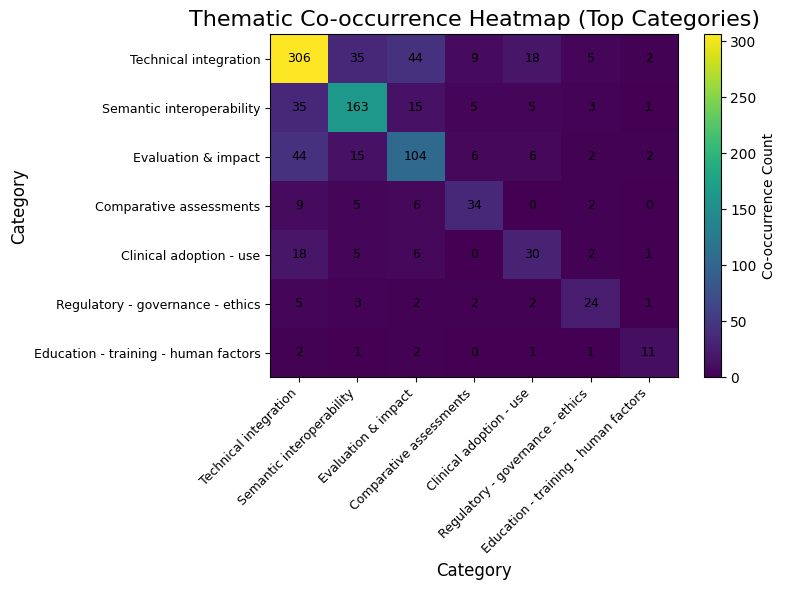

✅ `thematic_cooccurrence_heatmap_top7.csv` as CSV saved. 


In [35]:
import ast
import itertools

import matplotlib.pyplot as plt
import pandas as pd

from src.lib_dataset import DATASET
from src.lib_visualization import plt_savefig, dataframe_to_csv

TOP_N = 7

df = DATASET()


# Helper functions
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]


# df = df.rename(
#     columns={
#         "DEFA_assigned_category_v3": "assigned_category",
#     }
# )

df["assigned_category"] = df["assigned_category"].apply(safe_eval)

df_exploded = (
    df.explode("assigned_category")
    .dropna(subset=["assigned_category"])
    .assign(assigned_category=lambda x: x["assigned_category"].astype(str).str.strip())
)

df_exploded = df_exploded[df_exploded["assigned_category"] != ""]

top_categories = (
    df_exploded["assigned_category"]
    .value_counts()
    .head(TOP_N)
    .index
    .tolist()
)

if not top_categories:
    raise ValueError("No thematic categories found to build a co-occurrence matrix.")

coocc_df = pd.DataFrame(0, index=top_categories, columns=top_categories, dtype=int)

for categories in df["assigned_category"]:
    if not isinstance(categories, (list, tuple, set)):
        continue

    filtered = sorted({category for category in categories if category in top_categories})
    if not filtered:
        continue

    for category in filtered:
        coocc_df.loc[category, category] += 1

    for cat_a, cat_b in itertools.combinations(filtered, 2):
        coocc_df.loc[cat_a, cat_b] += 1
        coocc_df.loc[cat_b, cat_a] += 1

plt.figure(figsize=(8, 6))
plt.imshow(coocc_df, aspect="auto")
plt.colorbar(label="Co-occurrence Count")
plt.title("Thematic Co-occurrence Heatmap (Top Categories)", fontsize=16)
plt.xlabel("Category", fontsize=12)
plt.ylabel("Category", fontsize=12)
plt.xticks(range(len(coocc_df.columns)), coocc_df.columns, rotation=45, ha="right", fontsize=9)
plt.yticks(range(len(coocc_df.index)), coocc_df.index, fontsize=9)

for i in range(len(coocc_df.index)):
    for j in range(len(coocc_df.columns)):
        plt.text(j, i, f"{coocc_df.iloc[i, j]}", ha="center", va="center", fontsize=9)

plt.subplots_adjust(bottom=0.25, left=0.25)

plt_savefig(plt, "thematic_cooccurrence_heatmap_top7.png")
plt.show()
plt.close()

dataframe_to_csv(
    coocc_df.reset_index().rename(columns={"index": "Category"}),
    "thematic_cooccurrence_heatmap_top7.csv",
)

### Three-Field Plot (Authors–Keywords–Journals)
A three-field plot was constructed to visualize the relationships between prolific authors, high-frequency keywords, and leading journals. Links represent co-occurrence at the document level, thereby illustrating how key contributors, research topics, and publication venues are interconnected across the corpus.

In [36]:
import ast
import pandas as pd
import plotly.graph_objects as go
from src.config import OUTPUT_DIR
from src.lib_dataset import DATASET
from src.lib_visualization import dataframe_to_csv

# ---------------------- Settings -------------------------
TOP_N_AUTHORS = 10
TOP_N_KEYWORDS = 10
TOP_N_JOURNALS = 7
MIN_EDGE_WEIGHT = 2
MAX_LABEL_LENGTH = 32

df = DATASET()

# Helper functions 
def safe_eval(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return [] if pd.isna(value) else [value]
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else [parsed]
    except (ValueError, SyntaxError):
        return [] if pd.isna(value) else [value]

def clean_text_list(values):
    cleaned = []
    for value in values:
        if pd.isna(value):
            continue
        text = str(value).strip()
        if text == "":
            continue
        cleaned.append(text)
    return cleaned

def truncate_label(text, max_len=32):
    text = str(text).strip()
    return text if len(text) <= max_len else text[:max_len - 3] + "..."

def deduplicate_preserve_order(values):
    seen = set()
    result = []
    for value in values:
        if value not in seen:
            seen.add(value)
            result.append(value)
    return result

# ---------------------- Main use -------------------------
# Normalize fields
df["authors"] = df["authors"].apply(safe_eval) if "authors" in df.columns else [[] for _ in range(len(df))]
df["keywords"] = df["keywords"].apply(safe_eval) if "keywords" in df.columns else [[] for _ in range(len(df))]
df["journal_title"] = (
    df["journal_title"].fillna("").astype(str).str.strip()
    if "journal_title" in df.columns
    else ""
)

# Clean list fields
df["authors"] = df["authors"].apply(clean_text_list)
df["keywords"] = df["keywords"].apply(clean_text_list)

# Keep only valid rows
df = df[
    (df["authors"].apply(len) > 0) &
    (df["keywords"].apply(len) > 0) &
    (df["journal_title"] != "")
].copy()

if df.empty:
    raise ValueError("No valid records found with authors, keywords, and journal_title.")

# Global frequency summaries 
author_freq = (
    df.explode("authors")["authors"]
    .value_counts()
    .reset_index()
)
author_freq.columns = ["Author", "Documents"]

keyword_freq = (
    df.explode("keywords")["keywords"]
    .value_counts()
    .reset_index()
)
keyword_freq.columns = ["Keyword", "Documents"]

journal_freq = (
    df["journal_title"]
    .value_counts()
    .reset_index()
)
journal_freq.columns = ["Journal", "Documents"]

dataframe_to_csv(author_freq, "three_field_author_frequency.csv")
dataframe_to_csv(keyword_freq, "three_field_keyword_frequency.csv")
dataframe_to_csv(journal_freq, "three_field_journal_frequency.csv")

# Keep top entities 
top_authors = author_freq.head(TOP_N_AUTHORS)["Author"].tolist()
top_keywords = keyword_freq.head(TOP_N_KEYWORDS)["Keyword"].tolist()
top_journals = journal_freq.head(TOP_N_JOURNALS)["Journal"].tolist()

df["authors_filtered"] = df["authors"].apply(
    lambda values: [v for v in values if v in top_authors]
)
df["keywords_filtered"] = df["keywords"].apply(
    lambda values: [v for v in values if v in top_keywords]
)
df["journal_filtered"] = df["journal_title"].apply(
    lambda value: value if value in top_journals else None
)

df_plot = df[
    (df["authors_filtered"].apply(len) > 0) &
    (df["keywords_filtered"].apply(len) > 0) &
    (df["journal_filtered"].notna())
].copy()

if df_plot.empty:
    raise ValueError("No records remain after filtering to top authors, keywords, and journals.")

# Remove duplicates within each record
df_plot["authors_filtered"] = df_plot["authors_filtered"].apply(deduplicate_preserve_order)
df_plot["keywords_filtered"] = df_plot["keywords_filtered"].apply(deduplicate_preserve_order)

# Build Author -> Keyword edges
ak_rows = []
for _, row in df_plot.iterrows():
    for author in row["authors_filtered"]:
        for keyword in row["keywords_filtered"]:
            ak_rows.append((author, keyword))

author_keyword_df = (
    pd.DataFrame(ak_rows, columns=["Author", "Keyword"])
    .groupby(["Author", "Keyword"], as_index=False)
    .size()
    .rename(columns={"size": "Weight"})
)

author_keyword_df = author_keyword_df[author_keyword_df["Weight"] >= MIN_EDGE_WEIGHT].copy()

# Build Keyword -> Journal edges
kj_rows = []
for _, row in df_plot.iterrows():
    journal = row["journal_filtered"]
    for keyword in row["keywords_filtered"]:
        kj_rows.append((keyword, journal))

keyword_journal_df = (
    pd.DataFrame(kj_rows, columns=["Keyword", "Journal"])
    .groupby(["Keyword", "Journal"], as_index=False)
    .size()
    .rename(columns={"size": "Weight"})
)

keyword_journal_df = keyword_journal_df[keyword_journal_df["Weight"] >= MIN_EDGE_WEIGHT].copy()

if author_keyword_df.empty or keyword_journal_df.empty:
    raise ValueError(
        "No sufficient edge weights were found for the Three-Field Plot. "
        "Try lowering MIN_EDGE_WEIGHT."
    )

# Keep only connected keywords
connected_keywords = sorted(
    set(author_keyword_df["Keyword"]).intersection(set(keyword_journal_df["Keyword"]))
)

author_keyword_df = author_keyword_df[
    author_keyword_df["Keyword"].isin(connected_keywords)
].copy()

keyword_journal_df = keyword_journal_df[
    keyword_journal_df["Keyword"].isin(connected_keywords)
].copy()

if author_keyword_df.empty or keyword_journal_df.empty:
    raise ValueError("No connected author-keyword-journal structure could be constructed.")

# Re-rank nodes by connected weight
author_rank = (
    author_keyword_df.groupby("Author", as_index=False)["Weight"]
    .sum()
    .sort_values("Weight", ascending=False)
    .reset_index(drop=True)
)

keyword_rank_left = (
    author_keyword_df.groupby("Keyword", as_index=False)["Weight"]
    .sum()
    .rename(columns={"Weight": "AK_Weight"})
)

keyword_rank_right = (
    keyword_journal_df.groupby("Keyword", as_index=False)["Weight"]
    .sum()
    .rename(columns={"Weight": "KJ_Weight"})
)

keyword_rank = (
    keyword_rank_left.merge(keyword_rank_right, on="Keyword", how="outer")
    .fillna(0)
)
keyword_rank["Total_Weight"] = keyword_rank["AK_Weight"] + keyword_rank["KJ_Weight"]
keyword_rank = keyword_rank.sort_values("Total_Weight", ascending=False).reset_index(drop=True)

journal_rank = (
    keyword_journal_df.groupby("Journal", as_index=False)["Weight"]
    .sum()
    .sort_values("Weight", ascending=False)
    .reset_index(drop=True)
)

dataframe_to_csv(author_rank, "three_field_author_rank_connected.csv")
dataframe_to_csv(keyword_rank, "three_field_keyword_rank_connected.csv")
dataframe_to_csv(journal_rank, "three_field_journal_rank_connected.csv")

connected_authors = author_rank["Author"].tolist()
connected_keywords = keyword_rank["Keyword"].tolist()
connected_journals = journal_rank["Journal"].tolist()

# Create ordered node labels
author_nodes = [f"Author | {truncate_label(x, MAX_LABEL_LENGTH)}" for x in connected_authors]
keyword_nodes = [f"Keyword | {truncate_label(x, MAX_LABEL_LENGTH)}" for x in connected_keywords]
journal_nodes = [f"Journal | {truncate_label(x, MAX_LABEL_LENGTH)}" for x in connected_journals]

all_nodes = author_nodes + keyword_nodes + journal_nodes
node_map = {label: idx for idx, label in enumerate(all_nodes)}

author_label_map = {
    author: f"Author | {truncate_label(author, MAX_LABEL_LENGTH)}"
    for author in connected_authors
}
keyword_label_map = {
    keyword: f"Keyword | {truncate_label(keyword, MAX_LABEL_LENGTH)}"
    for keyword in connected_keywords
}
journal_label_map = {
    journal: f"Journal | {truncate_label(journal, MAX_LABEL_LENGTH)}"
    for journal in connected_journals
}

# Build Sankey links
sources = []
targets = []
values = []

# Author -> Keyword
for _, row in author_keyword_df.iterrows():
    source_label = author_label_map[row["Author"]]
    target_label = keyword_label_map[row["Keyword"]]
    sources.append(node_map[source_label])
    targets.append(node_map[target_label])
    values.append(int(row["Weight"]))

# Keyword -> Journal
for _, row in keyword_journal_df.iterrows():
    source_label = keyword_label_map[row["Keyword"]]
    target_label = journal_label_map[row["Journal"]]
    sources.append(node_map[source_label])
    targets.append(node_map[target_label])
    values.append(int(row["Weight"]))

# Plot
fig = go.Figure(
    data=[
        go.Sankey(
            arrangement="snap",
            node=dict(
                pad=16,
                thickness=18,
                line=dict(color="black", width=0.4),
                label=all_nodes,
            ),
            link=dict(
                source=sources,
                target=targets,
                value=values,
            ),
        )
    ]
)

fig.update_layout(
    title={
        "text": "Three-Field Plot (Authors–Keywords–Journals)",
        "x": 0.5,
    },
    font=dict(size=10),
)

# Save outputs
dataframe_to_csv(author_keyword_df, "three_field_author_keyword_edges.csv")
dataframe_to_csv(keyword_journal_df, "three_field_keyword_journal_edges.csv")

html_path = OUTPUT_DIR / "three_field_plot_authors_keywords_journals.html"
fig.write_html(str(html_path))
print("Saved HTML: three_field_plot_authors_keywords_journals.html")

try:
    fig.write_image(
        str(OUTPUT_DIR / "three_field_plot_authors_keywords_journals.png"),
        format="png",
        scale=2,
    )
    print("Saved PNG: three_field_plot_authors_keywords_journals.png")
except Exception as e:
    print(f"Could not save PNG (Plotly static export error): {e}")

fig.show()

✅ `three_field_author_frequency.csv` as CSV saved. 
✅ `three_field_keyword_frequency.csv` as CSV saved. 
✅ `three_field_journal_frequency.csv` as CSV saved. 
✅ `three_field_author_rank_connected.csv` as CSV saved. 
✅ `three_field_keyword_rank_connected.csv` as CSV saved. 
✅ `three_field_journal_rank_connected.csv` as CSV saved. 
✅ `three_field_author_keyword_edges.csv` as CSV saved. 
✅ `three_field_keyword_journal_edges.csv` as CSV saved. 
Saved HTML: three_field_plot_authors_keywords_journals.html
Could not save PNG (Plotly static export error): 
Image export using the "kaleido" engine requires the Kaleido package,
which can be installed using pip:

    $ pip install --upgrade kaleido

